In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
"""
food_weight_pipeline.py

Implements:
1) Faster R-CNN detection training (fine-tune) for 14 food classes + background
2) Inference -> crop detected boxes
3) Weight estimator using MobileNetV3 backbone + metadata -> Dense(64)->ReLU->Dense(32)->ReLU->Dense(1)
4) Training/eval loops and metrics

Notes:
- You must prepare annotations and a CSV (format described below).
- This script focuses on reproducible pipeline; heavy training requires GPU.
- Citation: Implementation follows "Vision-Based Approach for Food Weight Estimation from 2D Images". :contentReference[oaicite:2]{index=2}
"""

import os
import math
import time
import json
import random
from pathlib import Path
from typing import List, Tuple, Dict

import numpy as np
from PIL import Image
from sklearn.metrics import r2_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# -----------------------------
# Configuration / Hyperparams
# -----------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 15  # 14 food types + background
DETECTION_EPOCHS = 10
REGRESSION_EPOCHS = 10
DETECTION_BATCH_SIZE = 1   # paper used batch size 1 for Faster R-CNN
REGRESSION_BATCH_SIZE = 32
LR = 1e-4
IMAGE_SIZE = (224, 224)  # images resized as in the paper
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# -----------------------------
# Utilities & Metrics
# -----------------------------
def mse(y_true, y_pred): return np.mean((y_true - y_pred)**2)
def rmse(y_true, y_pred): return np.sqrt(mse(y_true, y_pred))
def mae(y_true, y_pred): return np.mean(np.abs(y_true - y_pred))
def mape(y_true, y_pred):
    eps = 1e-8
    return np.mean(np.abs((y_true - y_pred) / (y_true + eps))) * 100.0
def r2(y_true, y_pred): return r2_score(y_true, y_pred)

# -----------------------------
# DATASET: detection annotations
# -----------------------------
# Expect COCO-like or simple custom annotation JSON/CSV:
# For detection training, create a JSON per image with: boxes (x1,y1,x2,y2), labels (1..14), image_path
# For regression, create a CSV with columns: image_path, class_label (1..14), bbox (x1,y1,x2,y2), weight_grams

class DetectionDataset(Dataset):
    """
    Simple dataset expecting a list of dicts: {'image_path':..., 'boxes': [[x1,y1,x2,y2],...], 'labels':[int,...]}
    Use this for training Faster R-CNN.
    """
    def __init__(self, records: List[Dict], transforms=None):
        self.records = records
        self.transforms = transforms

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = Image.open(rec['image_path']).convert("RGB")
        w, h = img.size

        # boxes as list of [x1,y1,x2,y2]; labels are ints (1..14)
        boxes = torch.as_tensor(rec['boxes'], dtype=torch.float32)
        labels = torch.as_tensor(rec['labels'], dtype=torch.int64)

        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["image_id"] = torch.tensor([idx])

        if self.transforms:
            img = self.transforms(img)

        return img, target

# -----------------------------
# REGRESSION DATASET (cropped)
# -----------------------------
class RegressionDataset(Dataset):
    """
    Each row should already represent a cropped image sample and metadata:
    - 'crop_path' (path to cropped image resized to 224x224)
    - 'class_idx' (int 0..13)
    - 'area' (float)  # pixel area (width*height) or normalized
    - 'aspect_ratio' (float)
    - 'avg_intensity' (float)
    - 'weight' (float)  # ground truth weight (grams)
    CSV or JSON list structure is accepted.
    """
    def __init__(self, records: List[Dict], transforms=None):
        self.records = records
        self.transforms = transforms

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        img = Image.open(r['crop_path']).convert('RGB')
        if self.transforms:
            img_tensor = self.transforms(img)  # e.g. normalized tensor (C,H,W)
        else:
            to_tensor = transforms.ToTensor()
            img_tensor = to_tensor(img)

        # features: we'll use image feature α extracted from MobileNetV3,
        # but here we return the raw image and metadata; model code will extract α.
        meta = {
            'class_idx': r['class_idx'],
            'area': torch.tensor([r['area']], dtype=torch.float32),
            'aspect_ratio': torch.tensor([r['aspect_ratio']], dtype=torch.float32),
            'avg_intensity': torch.tensor([r['avg_intensity']], dtype=torch.float32)
        }
        weight = torch.tensor([r['weight']], dtype=torch.float32)

        return img_tensor, meta, weight

# -----------------------------
# MODEL: Detection (Faster R-CNN)
# -----------------------------
def get_detection_model(num_classes=NUM_CLASSES, pretrained_backbone=True):
    # Use a ResNet50-FPN backbone Faster R-CNN pretrained on COCO
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True, pretrained_backbone=pretrained_backbone)
    # Replace the classifier head with correct number of classes
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model

# -----------------------------
# MODEL: Weight Estimator
# -----------------------------
class MobileAlphaExtractor(nn.Module):
    """
    Returns a feature vector α from MobileNetV3 backbone.
    We'll use mobilenet_v3_small or large from torchvision, remove classifier.
    Output: 1-D feature vector (e.g., 576-d for mobilenet_v3_small last features) -> we can reduce via adaptive pool -> flatten -> fc to scalar α
    """
    def __init__(self, model_name='mobilenet_v3_small', pretrained=True, alpha_dim=1):
        super().__init__()
        if model_name == 'mobilenet_v3_small':
            base = torchvision.models.mobilenet_v3_small(pretrained=pretrained)
            feat_dim = base.classifier[0].in_features  # usually 576
            # remove classifier, keep features
            self.features = base.features
        else:
            base = torchvision.models.mobilenet_v3_large(pretrained=pretrained)
            feat_dim = base.classifier[0].in_features
            self.features = base.features

        self.global_pool = nn.AdaptiveAvgPool2d(1)
        # reduce to single scalar alpha (paper implies α is a single value)
        self.alpha_fc = nn.Linear(feat_dim, alpha_dim)

    def forward(self, x):
        # x: (B,3,224,224)
        feat_map = self.features(x)  # (B,feat_dim,H,W)
        pooled = self.global_pool(feat_map).reshape(x.shape[0], -1)  # (B, feat_dim)
        alpha = self.alpha_fc(pooled)  # (B, alpha_dim)
        return alpha  # use as numeric feature

class WeightEstimator(nn.Module):
    """
    Input vector X = [alpha (1), FT (class index or one-hot), A (area), AR (aspect ratio), API (avg pixel intensity)]
    We'll represent FT as either embedding of class index (paper concatenates FT; they didn't specify one-hot vs index — we'll use embedding)
    Then pass through Dense layers: (5 -> 64 -> 32 -> 1) as described.
    However because alpha may be >1-dim, adjust sizes accordingly.
    """
    def __init__(self, alpha_dim=1, num_food_classes=14, use_embedding=True):
        super().__init__()
        self.use_embedding = use_embedding
        if use_embedding:
            emb_dim = 8
            self.food_emb = nn.Embedding(num_food_classes, emb_dim)
            input_dim = alpha_dim + emb_dim + 3  # area, aspect_ratio, avg_intensity
        else:
            # if using one-hot, input increases
            input_dim = alpha_dim + num_food_classes + 3

        self.fc1 = nn.Linear(input_dim, 64)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)

    def forward(self, alpha, class_idx, area, aspect_ratio, avg_intensity):
        # alpha: (B, alpha_dim)
        if self.use_embedding:
            emb = self.food_emb(class_idx.long().squeeze(-1))  # (B, emb_dim)
        else:
            # expected class_idx one-hot already provided - not implemented here
            raise NotImplementedError("One-hot path not implemented. Use embeddings.")

        x = torch.cat([alpha, emb, area, aspect_ratio, avg_intensity], dim=1)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        out = self.fc3(x)
        return out

# -----------------------------
# Helper: crop image with bbox and compute metadata
# -----------------------------
def crop_and_save(image_path, box, out_path, resize=IMAGE_SIZE):
    """
    box: [x1,y1,x2,y2] in pixel coords
    """
    img = Image.open(image_path).convert("RGB")
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1 = max(0, x1); y1 = max(0, y1)
    x2 = min(img.width-1, x2); y2 = min(img.height-1, y2)
    crop = img.crop((x1, y1, x2, y2))
    crop_resized = crop.resize(resize)
    crop_resized.save(out_path)
    width, height = crop.size
    area = width * height
    aspect_ratio = width / (height + 1e-8)
    gray = np.array(crop.convert("L")) / 255.0
    avg_intensity = float(gray.mean())
    return area, aspect_ratio, avg_intensity

# -----------------------------
# TRAIN/INFER FUNCTIONS
# -----------------------------
def train_detection(model, dataset, device=DEVICE, epochs=DETECTION_EPOCHS, batch_size=DETECTION_BATCH_SIZE):
    model.to(device)
    model.train()
    data_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, collate_fn=lambda x: tuple(zip(*x)))
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(params, lr=LR)

    for epoch in range(epochs):
        epoch_loss = 0.0
        t0 = time.time()
        for imgs, targets in data_loader:
            imgs = list(img.to(device) for img in imgs)
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
            loss_dict = model(imgs, targets)
            losses = sum(loss for loss in loss_dict.values())
            optimizer.zero_grad()
            losses.backward()
            optimizer.step()
            epoch_loss += losses.item()
        print(f"[Det Train] Epoch {epoch+1}/{epochs} Loss: {epoch_loss:.4f} Time: {time.time()-t0:.1f}s")
    return model

def inference_detection_and_crop(model, records, out_dir, device=DEVICE, score_thresh=0.5):
    """
    records: list of {'image_path':...}
    Runs detection on each image, for each predicted box with score>score_thresh:
        - crops and saves crop to out_dir/<imagename>_obj<i>.jpg
        - yields a list of dicts for regression dataset (crop_path, class_idx, area, aspect_ratio, avg_intensity, weight if available)
    Note: If you have ground truth weight and bbox, you may instead use GT crops during training as in the paper.
    """
    os.makedirs(out_dir, exist_ok=True)
    model.to(device)
    model.eval()
    preprocess = transforms.Compose([
        transforms.Resize(IMAGE_SIZE),
        transforms.ToTensor(),
    ])
    results = []
    with torch.no_grad():
        for rec in records:
            img_path = rec['image_path']
            img = Image.open(img_path).convert("RGB")
            img_t = preprocess(img).to(device)
            out = model([img_t])[0]
            boxes = out['boxes'].cpu().numpy()
            scores = out['scores'].cpu().numpy()
            labels = out['labels'].cpu().numpy()
            # use predicted boxes above threshold
            for i, score in enumerate(scores):
                if score < score_thresh:
                    continue
                box = boxes[i].tolist()
                label = int(labels[i]) - 1  # model labels start at 1 for classes; convert to 0-index for embedding
                base = Path(img_path).stem
                crop_name = f"{base}_det{i}.jpg"
                crop_path = os.path.join(out_dir, crop_name)
                area, ar, avg_intensity = crop_and_save(img_path, box, crop_path)
                # If ground truth weight available in rec (e.g., rec.get('weight')), include it. Otherwise set to -1
                weight = rec.get('weight', -1.0)
                results.append({
                    'crop_path': crop_path,
                    'class_idx': label,
                    'area': float(area),
                    'aspect_ratio': float(ar),
                    'avg_intensity': float(avg_intensity),
                    'weight': float(weight)
                })
    return results

def train_regression(alpha_extractor, regressor, train_loader, val_loader=None, device=DEVICE, epochs=REGRESSION_EPOCHS):
    alpha_extractor.to(device)
    regressor.to(device)
    alpha_extractor.eval()  # we can freeze backbone; paper uses MobileNetV3 as backbone — can be trained or frozen. We'll freeze features.
    for p in alpha_extractor.parameters(): p.requires_grad = False

    params = [p for p in regressor.parameters() if p.requires_grad]
    optimizer = optim.Adam(params, lr=LR)
    criterion = nn.MSELoss()

    for epoch in range(epochs):
        regressor.train()
        epoch_losses = []
        for imgs, metas, weights in train_loader:
            imgs = imgs.to(device)
            class_idx = metas['class_idx'].to(device)
            area = metas['area'].to(device)
            ar = metas['aspect_ratio'].to(device)
            avg_int = metas['avg_intensity'].to(device)
            weights = weights.to(device)

            alpha = alpha_extractor(imgs)  # (B, alpha_dim)
            preds = regressor(alpha, class_idx, area, ar, avg_int).squeeze(1)
            loss = criterion(preds, weights.squeeze(1))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())
        avg_loss = float(np.mean(epoch_losses))
        print(f"[Reg Train] Epoch {epoch+1}/{epochs} MSE Loss: {avg_loss:.4f}")

        if val_loader is not None:
            eval_results = evaluate_regression(alpha_extractor, regressor, val_loader, device=device)
            print(f"  Val MSE: {eval_results['mse']:.4f} RMSE: {eval_results['rmse']:.4f} MAE: {eval_results['mae']:.4f} MAPE:{eval_results['mape']:.4f}% R2:{eval_results['r2']:.4f}")
    return regressor

def evaluate_regression(alpha_extractor, regressor, loader, device=DEVICE):
    alpha_extractor.to(device)
    regressor.to(device)
    alpha_extractor.eval()
    regressor.eval()
    y_true = []
    y_pred = []
    with torch.no_grad():
        for imgs, metas, weights in loader:
            imgs = imgs.to(device)
            class_idx = metas['class_idx'].to(device)
            area = metas['area'].to(device)
            ar = metas['aspect_ratio'].to(device)
            avg_int = metas['avg_intensity'].to(device)
            weights = weights.to(device)

            alpha = alpha_extractor(imgs)
            preds = regressor(alpha, class_idx, area, ar, avg_int).squeeze(1)
            y_true.extend(weights.cpu().numpy().squeeze().tolist())
            y_pred.extend(preds.cpu().numpy().tolist())

    y_true = np.array(y_true, dtype=float)
    y_pred = np.array(y_pred, dtype=float)
    return {
        'mse': mse(y_true, y_pred),
        'rmse': rmse(y_true, y_pred),
        'mae': mae(y_true, y_pred),
        'mape': mape(y_true, y_pred),
        'r2': r2(y_true, y_pred)
    }

# -----------------------------
# Example usage / pipeline
# -----------------------------
if __name__ == "__main__":
    # 1) Load detections annotations JSON or CSV (user must prepare)
    # For demonstration we expect a JSON list file with entries:
    # [{'image_path': '/path/img1.jpg', 'boxes': [[x1,y1,x2,y2]], 'labels': [1]}, ...]
    # Replace 'annotations_detection.json' with your file.
    DET_ANNOT_JSON = "annotations_detection.json"
    if not os.path.exists(DET_ANNOT_JSON):
        print("Please create detection annotation file 'annotations_detection.json'. See code comments for expected format.")
        # We stop here; user must prepare annotations to run real training.
    else:
        with open(DET_ANNOT_JSON, 'r') as f:
            det_records = json.load(f)

        # transforms: resize and to tensor for detection
        det_transforms = transforms.Compose([
            transforms.Resize(IMAGE_SIZE),
            transforms.ToTensor()
        ])
        det_dataset = DetectionDataset(det_records, transforms=det_transforms)
        detection_model = get_detection_model(num_classes=NUM_CLASSES)
        print("Starting Faster R-CNN training (this may be slow).")
        detection_model = train_detection(detection_model, det_dataset)

        # Save detection model
        torch.save(detection_model.state_dict(), "fasterrcnn_food.pth")
        print("Detection model saved to fasterrcnn_food.pth")

        # 2) Run inference on dataset to create crops dataset (or use GT crops if you prefer)
        crops_out_dir = "crops_from_detection"
        regression_records = inference_detection_and_crop(detection_model, det_records, crops_out_dir, score_thresh=0.6)
        # If you have ground truth weights in DET records, inference_detection_and_crop will copy them (if present).
        # Otherwise you need to create regression_records with weights (e.g., manually or using GT bboxes).

        # 3) Prepare regression dataset split (train/val/test). Here we do a random split:
        random.shuffle(regression_records)
        n = len(regression_records)
        ntrain = int(0.6 * n)
        nval = int(0.2 * n)
        train_records = regression_records[:ntrain]
        val_records = regression_records[ntrain:ntrain+nval]
        test_records = regression_records[ntrain+nval:]

        # produce transforms: normalize per paper mean/std (approx given in Table II)
        # The paper gives separate means for train/val/test; for simplicity we use common normalization.
        normalize = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.4890,0.4890,0.4890], std=[0.2301,0.2301,0.2301])  # paper mean/std (single-channel repeated)
        ])

        train_ds = RegressionDataset(train_records, transforms=normalize)
        val_ds = RegressionDataset(val_records, transforms=normalize)
        test_ds = RegressionDataset(test_records, transforms=normalize)

        train_loader = DataLoader(train_ds, batch_size=REGRESSION_BATCH_SIZE, shuffle=True, collate_fn=lambda x: collate_regression(x))
        val_loader = DataLoader(val_ds, batch_size=REGRESSION_BATCH_SIZE, shuffle=False, collate_fn=lambda x: collate_regression(x))
        test_loader = DataLoader(test_ds, batch_size=REGRESSION_BATCH_SIZE, shuffle=False, collate_fn=lambda x: collate_regression(x))

        # 4) Create alpha extractor and regressor
        alpha_extractor = MobileAlphaExtractor(model_name='mobilenet_v3_small', pretrained=True, alpha_dim=1)
        regressor = WeightEstimator(alpha_dim=1, num_food_classes=14, use_embedding=True)

        # 5) Train regression
        print("Starting regression training (MobileNetV3 backbone -> FC layers).")
        train_regression(alpha_extractor, regressor, train_loader, val_loader=val_loader)

        # 6) Evaluate on test set
        test_metrics = evaluate_regression(alpha_extractor, regressor, test_loader)
        print("Test Metrics:", test_metrics)
        # Save regression model
        torch.save({
            'alpha_state': alpha_extractor.state_dict(),
            'regressor_state': regressor.state_dict()
        }, "weight_estimator.pth")
        print("Regression model saved to weight_estimator.pth")

# -----------------------------
# Collate function for regression dataloader
# -----------------------------
def collate_regression(batch):
    # batch: list of (img_tensor, meta(dict), weight_tensor)
    imgs = torch.stack([b[0] for b in batch], dim=0)
    metas = {
        'class_idx': torch.stack([torch.tensor([b[1]['class_idx']], dtype=torch.long) for b in batch], dim=0),
        'area': torch.stack([b[1]['area'] for b in batch], dim=0),
        'aspect_ratio': torch.stack([b[1]['aspect_ratio'] for b in batch], dim=0),
        'avg_intensity': torch.stack([b[1]['avg_intensity'] for b in batch], dim=0)
    }
    weights = torch.stack([b[2] for b in batch], dim=0)
    return imgs, metas, weights


Please create detection annotation file 'annotations_detection.json'. See code comments for expected format.


In [ ]:
import pandas as pd
import os
import pandas as pd
import numpy as np
from PIL import Image





# === Paths ===
base_dir = "/content/drive/MyDrive/TomatoF" # folder containing your tomato.csv and images
csv_path = os.path.join(base_dir, "tomato.csv")
output_csv = os.path.join(base_dir, "tomato_ready.csv")

# === Read CSV ===
df = pd.read_csv(csv_path)

# === Function to compute features ===
def compute_image_features(image_path):
    try:
        with Image.open(image_path).convert("RGB") as img:
            width, height = img.size
            area = width * height
            aspect_ratio = width / (height + 1e-8)
            gray = np.array(img.convert("L")) / 255.0
            avg_intensity = gray.mean()
        return area, aspect_ratio, avg_intensity
    except Exception as e:
        print(f"Error reading {image_path}: {e}")
        return np.nan, np.nan, np.nan

# === Compute features for each image ===
areas, aspect_ratios, intensities = [], [], []

for _, row in df.iterrows():

    img_path = os.path.join(base_dir+"/Tomato-Images/Tomato", row["Image Name"])
    area, ar, intensity = compute_image_features(img_path)
    areas.append(area)
    aspect_ratios.append(ar)
    intensities.append(intensity)

df["crop_path"] = df["Image Name"].apply(lambda x: os.path.join(base_dir, x))
df["class_idx"] = 0  # all are tomatoes
df["area"] = areas
df["aspect_ratio"] = aspect_ratios
df["avg_intensity"] = intensities
df.rename(columns={"Weight": "weight"}, inplace=True)

# === Save ready dataset ===
cols = ["crop_path", "class_idx", "area", "aspect_ratio", "avg_intensity", "weight"]
df_ready = df[cols]
df_ready.to_csv(output_csv, index=False)
print(f"✅ Saved processed dataset to: {output_csv}")
print(df_ready.head())



✅ Saved processed dataset to: /content/drive/MyDrive/TomatoF/tomato_ready.csv
                                     crop_path  class_idx      area  \
0  /content/drive/MyDrive/TomatoF/IMG_1810.JPG          0  12192768   
1  /content/drive/MyDrive/TomatoF/IMG_1811.JPG          0  12192768   
2  /content/drive/MyDrive/TomatoF/IMG_1812.JPG          0  12192768   
3  /content/drive/MyDrive/TomatoF/IMG_1813.JPG          0  12192768   
4  /content/drive/MyDrive/TomatoF/IMG_1814.JPG          0  12192768   

   aspect_ratio  avg_intensity  weight  
0          0.75       0.642794      92  
1          0.75       0.635428      92  
2          0.75       0.632322      95  
3          0.75       0.631371      95  
4          0.75       0.648659      57  


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score


# ==========================
# CONFIG
# ==========================
csv_path = "/content/drive/MyDrive/TomatoF/tomato_ready.csv"

# ==========================
# CONFIG
# ==========================
csv_path = "/content/drive/MyDrive/TomatoF/tomato_ready.csv"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 8
epochs = 30
lr = 5e-5

# ==========================
# PREPARE DATA
# ==========================
df = pd.read_csv(csv_path)
meta_cols = ["class_idx", "area", "aspect_ratio", "avg_intensity"]

# 1. Force all metadata columns and weight to numeric (non-numeric → NaN)
for c in meta_cols + ["weight"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# 2. Drop rows with any missing or invalid data
df = df.dropna(subset=meta_cols + ["weight", "crop_path"]).reset_index(drop=True)

# 3. Verify all are float now
print("Data types before scaling:\n", df[meta_cols + ["weight"]].dtypes)

# 4. Scale the numeric columns
scaler = StandardScaler()
df[meta_cols] = scaler.fit_transform(df[meta_cols])

# 5. Convert to float32 explicitly (important for PyTorch)
df[meta_cols + ["weight"]] = df[meta_cols + ["weight"]].astype(np.float32)

# 6. Save cleaned version (optional)
df.to_csv("/content/drive/MyDrive/TomatoF/tomato_ready_clean.csv", index=False)

# 7. Sanity check
print("✅ Cleaned data shape:", df.shape)
print(df[meta_cols + ["weight"]].head())
print(df.dtypes)
# ==========================
# DATASET
# ==========================
class TomatoDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
      row = self.df.iloc[idx]
      img = Image.open(row['crop_path']).convert("RGB")
      if self.transform:
          img = self.transform(img)
      # Force conversion to float32 tensor the safe way
      features = torch.tensor(
          np.array(row[meta_cols].astype(np.float32).to_list(), dtype=np.float32),
          dtype=torch.float32
      )
      weight = torch.tensor(float(row['weight']), dtype=torch.float32)
      return img, features, weight

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.489, 0.489, 0.489], std=[0.2301, 0.2301, 0.2301])
])

dataset = TomatoDataset(df, transform)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = torch.utils.data.random_split(dataset, [train_size, val_size])
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

# ==========================
# MODEL
# ==========================
class WeightEstimator(nn.Module):
    def __init__(self):
        super().__init__()
        base = models.mobilenet_v3_small(pretrained=True)
        for param in base.features.parameters():
            param.requires_grad = False  # freeze backbone

        self.features = base.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.alpha_fc = nn.Linear(576, 1)
        self.fc = nn.Sequential(
            nn.Linear(1 + len(meta_cols), 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, img, meta):
        x = self.features(img)
        x = self.pool(x).flatten(1)
        alpha = self.alpha_fc(x)
        x = torch.cat([alpha, meta], dim=1)
        return self.fc(x).squeeze(1)

model = WeightEstimator().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

# ==========================
# TRAIN LOOP
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for imgs, meta, weights in train_loader:
        imgs, meta, weights = imgs.to(device), meta.to(device), weights.to(device)
        optimizer.zero_grad()
        preds = model(imgs, meta)
        loss = criterion(preds, weights)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)

    # ----- Validation -----
    model.eval()
    val_loss = 0.0
    preds_all, true_all = [], []
    with torch.no_grad():
        for imgs, meta, weights in val_loader:
            imgs, meta, weights = imgs.to(device), meta.to(device), weights.to(device)
            preds = model(imgs, meta)
            val_loss += criterion(preds, weights).item()
            preds_all.extend(preds.cpu().numpy())
            true_all.extend(weights.cpu().numpy())

    val_loss /= len(val_loader)
    preds_all, true_all = np.array(preds_all), np.array(true_all)

    # --- Compute metrics ---
    rmse = np.sqrt(np.mean((preds_all - true_all)**2))
    mae = mean_absolute_error(true_all, preds_all)
    r2 = r2_score(true_all, preds_all)

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Train MSE: {train_loss:.4f} | "
          f"Val MSE: {val_loss:.4f} | "
          f"RMSE: {rmse:.3f} | "
          f"MAE: {mae:.3f} | "
          f"R²: {r2:.3f}")
torch.save(model.state_dict(), "/content/drive/MyDrive/tomato_weight_model.pth")
print("✅ Model saved to /mnt/data/tomato_weight_model.pth")

# ==========================
# INFERENCE FUNCTION
# ==========================




Data types before scaling:
 class_idx          int64
area               int64
aspect_ratio     float64
avg_intensity    float64
weight             int64
dtype: object
✅ Cleaned data shape: (45, 6)
   class_idx  area  aspect_ratio  avg_intensity  weight
0        0.0   0.0  1.110223e-16       0.614905    92.0
1        0.0   0.0  1.110223e-16      -0.365445    92.0
2        0.0   0.0  1.110223e-16      -0.778794    95.0
3        0.0   0.0  1.110223e-16      -0.905375    95.0
4        0.0   0.0  1.110223e-16       1.395383    57.0
crop_path         object
class_idx        float32
area             float32
aspect_ratio     float32
avg_intensity    float32
weight           float32
dtype: object


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V3_Small_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch [1/30] Train MSE: 4660.0605 | Val MSE: 3453.6461 | RMSE: 65.286 | MAE: 63.917 | R²: -23.102
Epoch [2/30] Train MSE: 4907.7025 | Val MSE: 3452.5612 | RMSE: 65.278 | MAE: 63.909 | R²: -23.096
Epoch [3/30] Train MSE: 4570.1254 | Val MSE: 3451.5199 | RMSE: 65.270 | MAE: 63.901 | R²: -23.091
Epoch [4/30] Train MSE: 4772.5050 | Val MSE: 3450.4397 | RMSE: 65.262 | MAE: 63.893 | R²: -23.085
Epoch [5/30] Train MSE: 4626.6937 | Val MSE: 3449.3501 | RMSE: 65.253 | MAE: 63.884 | R²: -23.078
Epoch [6/30] Train MSE: 4741.4050 | Val MSE: 3448.2836 | RMSE: 65.245 | MAE: 63.876 | R²: -23.072
Epoch [7/30] Train MSE: 4821.8573 | Val MSE: 3447.1797 | RMSE: 65.237 | MAE: 63.867 | R²: -23.066
Epoch [8/30] Train MSE: 4696.3313 | Val MSE: 3446.0162 | RMSE: 65.228 | MAE: 63.857 | R²: -23.059
Epoch [9/30] Train MSE: 4836.8157 | Val MSE: 3444.8354 | RMSE: 65.218 | MAE: 63.848 | R²: -23.052
Epoch [10/30] Train MSE: 4875.7645 | Val MSE: 3443.6261 | RMSE: 65.209 | MAE: 63.838 | R²: -23.045
Epoch [11/30] Train

In [ ]:
from PIL import Image
import os
import pandas as pd

csv_path = "/content/drive/MyDrive/TomatoF/tomato_ready.csv"
base_dir = os.path.dirname(csv_path)
df = pd.read_csv(csv_path)

def compute_image_features(img_path):
    with Image.open(img_path).convert("RGB") as img:
        w, h = img.size
        area = w * h
        aspect_ratio = w / (h + 1e-8)
        gray = np.array(img.convert("L")) / 255.0
        avg_intensity = gray.mean()
    return area, aspect_ratio, avg_intensity

areas, ars, intensities = [], [], []
for p in df["crop_path"]:
    area, ar, ai = compute_image_features(p)
    areas.append(area)
    ars.append(ar)
    intensities.append(ai)

df["area"] = areas
df["aspect_ratio"] = ars
df["avg_intensity"] = intensities
df.to_csv("/content/drive/MyDrive/TomatoF/tomato_ready_fixed.csv", index=False)
print("✅ Fixed CSV saved: tomato_ready_fixed.csv")


✅ Fixed CSV saved: tomato_ready_fixed.csv


In [ ]:
# ==========================
# INFERENCE FUNCTION
# ==========================
import torch
from PIL import Image
import numpy as np

def predict_weight(model, image_path, scaler, meta_defaults=None):
    """
    Predicts tomato weight for a new image using trained model.
    - model: trained WeightEstimator
    - image_path: path to tomato image (string)
    - scaler: StandardScaler fitted on training data
    - meta_defaults: dict for avg aspect_ratio, avg_intensity, etc. (optional)
    """
    model.eval()
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.489, 0.489, 0.489], std=[0.2301, 0.2301, 0.2301])
    ])

    # --- Load image ---
    img = Image.open(image_path).convert("RGB")
    img_t = transform(img).unsqueeze(0).to(device)

    # --- Compute metadata automatically if not given ---
    w, h = img.size
    area = w * h
    aspect_ratio = w / (h + 1e-8)
    gray = np.array(img.convert("L")) / 255.0
    avg_intensity = gray.mean()

    # --- Build meta vector ---
    if meta_defaults is None:
        meta_defaults = {'class_idx': 0}
    meta_vals = np.array([
        meta_defaults['class_idx'],
        area,
        aspect_ratio,
        avg_intensity
    ]).reshape(1, -1)

    # --- Apply same scaler used during training ---
    meta_scaled = scaler.transform(meta_vals)
    meta_t = torch.tensor(meta_scaled, dtype=torch.float32).to(device)

    # --- Predict ---
    with torch.no_grad():
        pred = model(img_t, meta_t)
    return float(pred.item())

# Load your trained model
model.load_state_dict(torch.load("/content/drive/MyDrive/tomato_weight_model.pth", map_location=device))
model.eval()

# Load same scaler used for training
import joblib
joblib.dump(scaler, "/content/drive/MyDrive/tomato_scaler.pkl")

# Example prediction
img_path = "/content/drive/MyDrive/TomatoF/IMG_1810.JPG"  # change to your image
pred_weight = predict_weight(model, img_path, scaler)
print(f"🍅 Estimated Weight: {pred_weight:.2f} grams")



🍅 Estimated Weight: 0.53 grams


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127813 (\N{TOMATO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


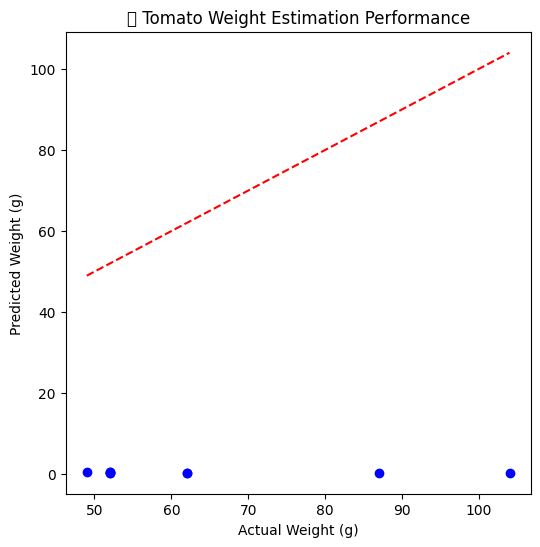

In [ ]:
import matplotlib.pyplot as plt

model.eval()
preds_all, true_all = [], []
with torch.no_grad():
    for imgs, meta, weights in val_loader:
        imgs, meta = imgs.to(device), meta.to(device)
        preds = model(imgs, meta)
        preds_all.extend(preds.cpu().numpy())
        true_all.extend(weights.cpu().numpy())

plt.figure(figsize=(6,6))
plt.scatter(true_all, preds_all, color='blue')
plt.plot([min(true_all), max(true_all)], [min(true_all), max(true_all)], 'r--')
plt.xlabel("Actual Weight (g)")
plt.ylabel("Predicted Weight (g)")
plt.title("🍅 Tomato Weight Estimation Performance")
plt.show()


In [2]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118  # or your correct torch wheel
!pip install scikit-image opencv-python pandas scikit-learn matplotlib tqdm pillow
!pip install scikit-optimize

Looking in indexes: https://download.pytorch.org/whl/cu118
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 5.5 MB/s eta 0:00:00


In [4]:
#!/usr/bin/env python3
"""
Complete pipeline:
1) Inputs: image_folder (settable) + CSV with columns: Image Name, Weight, View, Tomato ID
2) For each image: convert to grayscale -> Otsu threshold -> find bounding box (ground truth)
   (grayscale file temporarily saved and deleted afterwards to match requirement)
3) Split dataset into train/val/test = 80:10:10
4) Resize all images to (224,224)
5) Keep RGB pixel values, scale to [0,1], then normalize per-subset with subset mean/std
6) Random horizontal flip on training images
7) Train Faster R-CNN (ResNet-50-FPN backbone). Adam optimizer.
8) After detection, crop detected regions and save crops for next stage
9) For each crop: extract features:
   a) MobileNetV3 backbone feature (pooled scalar)
   b) Image Area (H * W)
   c) Aspect Ratio (W / H)
   d) Average Pixel Intensity (mean over pixels)
10) Input vector of 4 features -> 3-layer FC network: 4 -> 64 -> 32 -> 1 (ReLU between)
11) Loss: MSE. Optimizer: Adam.
12) Bayesian optimization (skopt) after each epoch: 5 iterations using GP surrogate and EI acquisition.
13) 3 epochs total.
14) Print MSE, MAE, R2 on test set.
15) NOTE: Otsu NOT used for inference.
"""

# -----------------------
# Install dependencies (uncomment the next lines if running in a fresh environment)
# -----------------------
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118  # or your correct torch wheel
# !pip install scikit-image opencv-python pandas scikit-learn matplotlib tqdm pillow
# !pip install scikit-optimize

import os
import shutil
import random
from pathlib import Path
import tempfile
import math
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.transforms import functional as F
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.ops import box_iou

from skimage import io, color
from skimage.filters import threshold_otsu
import cv2

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Bayesian optimization
from skopt import gp_minimize
from skopt.space import Real
from skopt.utils import use_named_args

# -----------------------
# Config
# -----------------------
INPUT_IMAGE_FOLDER = "/content/drive/MyDrive/TomatoF"   # <<--- edit this path to your input folder containing the images
CSV_PATH = "/content/drive/MyDrive/TomatoF/tomato.csv"      # <<--- CSV with columns: Image Name, Weight, View, Tomato ID
CROPS_DIR = "/content/drive/MyDrive/TomatoF/detected_crops"
PREPROCESSED_DIR = "/content/drive/MyDrive/preprocessed_images"  # resized images (224x224) for detector training
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42

# Detector training hyperparams (you can change)
DETECTOR_LR = 1e-4
DETECTOR_EPOCHS = 3   # keep small for demo; change as necessary
DETECTOR_BATCH_SIZE = 1  # detection usually uses 1

# Weight estimation MLP training
MLP_EPOCHS = 3 # as requested
MLP_BATCH_SIZE = 32

# Bayesian optimization config (per epoch)
BO_N_CALLS = 5 # as requested
BO_INITIAL_POINTS = 2

IMG_SIZE = (224, 224)
RANDOM_FLIP_PROB = 0.5

# Ensure reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Create directories
os.makedirs(CROPS_DIR, exist_ok=True)
os.makedirs(PREPROCESSED_DIR, exist_ok=True)

# -----------------------
# Helper: Otsu-based bbox extraction
# -----------------------
def otsu_bbox_from_image(img_path, tmp_gray_path=None):
    """
    1) Convert to grayscale
    2) Save grayscale image temporarily if tmp_gray_path provided
    3) Use Otsu thresholding to create mask
    4) Find largest contour and return bbox (x, y, w, h)
    5) Delete tmp grayscale file if it was saved
    """
    img = io.imread(img_path)
    if img.ndim == 3:
        gray = color.rgb2gray(img)  # values in [0,1]
        gray_uint8 = (gray * 255).astype(np.uint8)
    else:
        gray_uint8 = (img * 255).astype(np.uint8) if img.max() <= 1 else img.astype(np.uint8)

    # optionally save grayscale to disk and then delete
    if tmp_gray_path:
        cv2.imwrite(tmp_gray_path, gray_uint8)

    # Otsu threshold
    try:
        th = threshold_otsu(gray_uint8)
    except Exception:
        th = 128
    _, mask = cv2.threshold(gray_uint8, int(th), 255, cv2.THRESH_BINARY)

    # find contours
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        h, w = gray_uint8.shape[:2]
        return (0, 0, w, h)  # fallback full image

    # pick largest contour by area
    largest = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest)

    # delete grayscale file if saved
    if tmp_gray_path and os.path.exists(tmp_gray_path):
        os.remove(tmp_gray_path)

    return (x, y, w, h)

# -----------------------
# Step 1: Read CSV and build dataset list
# -----------------------
df = pd.read_csv(CSV_PATH)
required_cols = ['Image Name', 'Weight', 'View', 'Tomato ID']
for c in required_cols:
    if c not in df.columns:
        raise ValueError(f"CSV must contain column: {c}")

# Build a list of samples
samples = []
for _, row in df.iterrows():
    img_name = row['Image Name']
    weight = float(row['Weight'])
    img_path = os.path.join(INPUT_IMAGE_FOLDER, img_name)
    if not os.path.exists(img_path):
        print(f"Warning: {img_path} not found — skipping")
        continue
    samples.append({"img_path": img_path, "weight": weight, "view": row['View'], "id": row['Tomato ID']})

if len(samples) == 0:
    raise RuntimeError("No images found. Check INPUT_IMAGE_FOLDER and CSV_PATH.")

# -----------------------
# Step 2: Use Otsu thresholding to generate ground-truth bboxes
#   (grayscale temp files are deleted after)
# -----------------------
print("Generating ground-truth boxes via Otsu thresholding (grayscale saved then removed)...")
gt_records = []  # each record: img_path, weight, bbox(x,y,w,h)
tmpdir = tempfile.mkdtemp(prefix="tmp_gray_")
for s in tqdm(samples):
    img_path = s["img_path"]
    tmp_gray = os.path.join(tmpdir, Path(img_path).stem + "_gray.png")
    bbox = otsu_bbox_from_image(img_path, tmp_gray_path=tmp_gray)
    gt_records.append({"img_path": img_path, "weight": s["weight"], "bbox": bbox, "view": s["view"], "id": s["id"]})

# Remove the tmpdir (all grayscale images removed by function, but ensure)
try:
    shutil.rmtree(tmpdir)
except Exception:
    pass

# -----------------------
# Step 3: Split into train/val/test (80:10:10)
# -----------------------
paths = [r["img_path"] for r in gt_records]
weights = [r["weight"] for r in gt_records]
bbs = [r["bbox"] for r in gt_records]

train_idx, temp_idx = train_test_split(range(len(paths)), test_size=0.2, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=SEED)  # split 0.2 into 0.1 and 0.1

splits = {'train': train_idx, 'val': val_idx, 'test': test_idx}
print(f"Dataset sizes -> train: {len(train_idx)}, val: {len(val_idx)}, test: {len(test_idx)}")

# -----------------------
# Step 4 & 5: Resize all images to (224,224) and save into PREPROCESSED_DIR / subset folders
# Also store the resized RGB arrays for normalization step
# -----------------------
print("Resizing images to 224x224 and writing preprocessed copies...")
subset_images = {'train': [], 'val': [], 'test': []}  # each item: dict with keys img (np array RGB float [0,1]), bbox (rescaled), weight
for split_name, idxs in splits.items():
    out_dir = os.path.join(PREPROCESSED_DIR, split_name)
    os.makedirs(out_dir, exist_ok=True)
    for i in idxs:
        rec = gt_records[i]
        img = io.imread(rec["img_path"])
        # Ensure RGB
        if img.ndim == 2:
            img = np.stack([img] * 3, axis=-1)
        if img.shape[2] == 4:
            img = img[..., :3]
        # original bbox coordinates were on original image. We'll compute scaled bbox after resize.
        orig_h, orig_w = img.shape[:2]
        x, y, w, h = rec["bbox"]
        # Resize
        resized = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)
        # compute scale
        scale_x = IMG_SIZE[1] / orig_w
        scale_y = IMG_SIZE[0] / orig_h
        bx = int(round(x * scale_x))
        by = int(round(y * scale_y))
        bw = int(round(w * scale_x))
        bh = int(round(h * scale_y))
        # clamp
        bx = max(0, min(bx, IMG_SIZE[1] - 1))
        by = max(0, min(by, IMG_SIZE[0] - 1))
        bw = max(1, min(bw, IMG_SIZE[1] - bx))
        bh = max(1, min(bh, IMG_SIZE[0] - by))
        # save resized image to disk (RGB)
        out_path = os.path.join(out_dir, Path(rec["img_path"]).name)
        io.imsave(out_path, resized.astype(np.uint8))
        subset_images[split_name].append({
            "img_path": out_path,
            "img_array": (resized.astype(np.float32) / 255.0),  # scaled to [0,1] right away
            "bbox": (bx, by, bw, bh),
            "weight": rec["weight"]
        })
print("Resizing complete.")

# -----------------------
# Step 6 & 7 done: at this point images are RGB and scaled to [0,1]
# Step 8: compute per-subset mean/std and normalize
# -----------------------
print("Computing subset-wise mean/std and applying normalization...")
subset_meanstd = {}
for split_name in ['train', 'val', 'test']:
    arrays = [d['img_array'] for d in subset_images[split_name]]
    if len(arrays) == 0:
        raise RuntimeError(f"No images in split {split_name}")
    # stack channel wise
    stacked = np.stack(arrays, axis=0)  # (N, H, W, C)
    # compute per-channel mean/std
    # change to (N, C, H, W) for channel axis
    stacked_ch = np.transpose(stacked, (0, 3, 1, 2))
    mean = stacked_ch.mean(axis=(0, 2, 3))
    std = stacked_ch.std(axis=(0, 2, 3))
    subset_meanstd[split_name] = {'mean': mean, 'std': std}
    # normalize each stored img_array
    for d in subset_images[split_name]:
        # (H, W, C) -> (C, H, W)
        img_ch = np.transpose(d['img_array'], (2, 0, 1))
        img_ch = (img_ch - mean[:, None, None]) / (std[:, None, None] + 1e-9)
        d['img_array_norm'] = img_ch  # normalized tensor-like np array

print("Normalization stats per subset:")
for s, v in subset_meanstd.items():
    print(f"{s}: mean={v['mean']}, std={v['std']}")

# -----------------------
# Step 9: Random horizontal flip for training set will be applied on-the-fly in dataset
# -----------------------

# -----------------------
# Create custom Dataset for Faster R-CNN training
# Each item returns: PIL image (Tensor) and target dict with boxes and labels
# -----------------------
class DetectionDataset(Dataset):
    def __init__(self, records, transforms=None, normalize_mean=None, normalize_std=None, apply_flip=False):
        """
        records: list of dicts with keys img_path, bbox (x,y,w,h), weight (unused here)
        transforms: torchvision transforms to apply to the image (expecting normalized numpy arrays)
        normalize_mean/std not used because we already normalized per-subset; but keep placeholder
        apply_flip: whether to randomly horizontally flip (for training)
        """
        self.records = records
        self.apply_flip = apply_flip

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        img = io.imread(r['img_path'])  # uint8 HWC
        img = img.astype(np.float32) / 255.0  # [0,1]
        # convert to tensor CHW
        img_t = torch.from_numpy(np.transpose(img, (2,0,1))).float()
        # targets: boxes in [x1,y1,x2,y2], labels -> single class 1 (food)
        x, y, w, h = r['bbox']
        boxes = torch.tensor([[x, y, x + w, y + h]], dtype=torch.float32)
        labels = torch.tensor([1], dtype=torch.int64)  # we set 1 as "food" (single-class detection)
        target = {"boxes": boxes, "labels": labels}
        # optionally apply random horizontal flip on both image and box
        if self.apply_flip and random.random() < RANDOM_FLIP_PROB:
            img_t = torch.flip(img_t, dims=[2])  # horizontal flip along width dimension
            _, H, W = img_t.shape
            # flip box
            x1, y1, x2, y2 = boxes[0]
            new_x1 = W - x2
            new_x2 = W - x1
            boxes = torch.tensor([[new_x1, y1, new_x2, y2]], dtype=torch.float32)
            target["boxes"] = boxes
        return img_t, target

def collate_fn(batch):
    imgs = [b[0] for b in batch]
    targets = [b[1] for b in batch]
    return imgs, targets

# Build detection datasets and dataloaders (train uses flip)
det_train_ds = DetectionDataset(subset_images['train'], apply_flip=True)
det_val_ds = DetectionDataset(subset_images['val'], apply_flip=False)
det_test_ds = DetectionDataset(subset_images['test'], apply_flip=False)

det_train_loader = DataLoader(det_train_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
det_val_loader = DataLoader(det_val_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
det_test_loader = DataLoader(det_test_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

# -----------------------
# Step 10: Faster R-CNN with ResNet backbone initialization
# Single-class detection (food vs background)
# -----------------------
print("Initializing Faster R-CNN (ResNet-50-FPN) ...")
num_classes = 2  # background + food
detector = fasterrcnn_resnet50_fpn(pretrained=True)
# replace the head classifier to match num_classes
in_features = detector.roi_heads.box_predictor.cls_score.in_features
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
detector.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
detector.to(DEVICE)

optimizer_det = optim.Adam(detector.parameters(), lr=DETECTOR_LR)

# training loop for detector
print("Training Faster R-CNN detector...")
detector.train()
for epoch in range(DETECTOR_EPOCHS):
    epoch_loss = 0.0
    for images, targets in tqdm(det_train_loader, desc=f"Detector Epoch {epoch+1}/{DETECTOR_EPOCHS}"):
        images = [img.to(DEVICE) for img in images]
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
        loss_dict = detector(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        optimizer_det.zero_grad()
        losses.backward()
        optimizer_det.step()
        epoch_loss += losses.item()
    print(f"Detector epoch {epoch+1} loss: {epoch_loss:.4f}")

print("Detector training complete.")

# -----------------------
# Step 11: Use detector to create crops (detected bounding boxes)
# Save crops to CROPS_DIR/{split}/
# -----------------------
print("Running detector on all splits to generate detected crops...")
detector.eval()
with torch.no_grad():
    for split_name in ['train', 'val', 'test']:
        split_out = os.path.join(CROPS_DIR, split_name)
        os.makedirs(split_out, exist_ok=True)
        records = subset_images[split_name]
        for idx, rec in enumerate(tqdm(records, desc=f"Detect & crop {split_name}")):
            img = io.imread(rec['img_path']).astype(np.float32) / 255.0
            img_t = torch.from_numpy(np.transpose(img, (2,0,1))).float().to(DEVICE)
            outputs = detector([img_t])
            # outputs[0]['boxes'] [N,4], scores [N]
            boxes = outputs[0].get('boxes', torch.empty((0,4))).cpu().numpy()
            scores = outputs[0].get('scores', torch.empty((0,))).cpu().numpy() # <<< FIX: Move scores to CPU and convert to numpy
            if len(boxes) == 0:
                # fallback to ground-truth bbox
                x,y,w,h = rec['bbox']
                boxes = np.array([[x,y,x+w,y+h]], dtype=np.int32)
                chosen_box = boxes[0]
            else:
                # choose highest-score box
                best_idx = int(np.argmax(scores))
                chosen_box = boxes[best_idx].astype(int)
            x1,y1,x2,y2 = chosen_box
            # clamp
            H, W = img.shape[:2]
            x1, y1, x2, y2 = max(0, x1), max(0,y1), min(W-1,x2), min(H-1,y2)
            crop = img[y1:y2+1, x1:x2+1, :]
            # Save cropped image for feature extraction
            out_path = os.path.join(split_out, f"{Path(rec['img_path']).stem}_crop.png")
            io.imsave(out_path, (crop * 255).astype(np.uint8))
            rec.setdefault('detected_crop_path', out_path)
print("Crops generated and saved.")

# -----------------------
# Step 12: Feature extraction per crop using MobileNetV3 backbone
# We'll extract a feature vector per crop:
#   a) backbone scalar alpha = global pooled feature mean
#   b) Image area = H*W
#   c) Aspect ratio = W/H
#   d) Average pixel intensity = mean of pixels (grayscale)
# -----------------------
print("Preparing MobileNetV3 backbone for feature extraction...")
mobilenet_weights = MobileNet_V3_Large_Weights.IMAGENET1K_V2
mobilenet = mobilenet_v3_large(weights=mobilenet_weights).to(DEVICE)
mobilenet.eval()
# remove the classifier head: keep features and adaptive pooling
# mobilenet.features -> feature map
# final pooling uses mobilenet.classifier normally; we'll use AdaptiveAvgPool2d manually
pool = nn.AdaptiveAvgPool2d((1,1)).to(DEVICE)

def extract_features_from_crop(crop_path):
    img = io.imread(crop_path).astype(np.float32) / 255.0  # HWC [0,1]
    if img.ndim == 2:
        img = np.stack([img]*3, axis=-1)
    if img.shape[2] == 4:
        img = img[..., :3]
    # ensure tensor shape expected by mobilenet (C,H,W), normalized with mobilenet's weights transforms
    # apply mobilenet preprocessing
    preprocess = mobilenet_weights.transforms()
    pil = (img * 255).astype(np.uint8)
    # use PIL image via skimage -> convert to uint8 array then to PIL
    from PIL import Image
    pil_img = Image.fromarray(pil)
    inp = preprocess(pil_img).unsqueeze(0).to(DEVICE)  # shape (1,3,H,W)
    with torch.no_grad():
        feat_map = mobilenet.features(inp)  # shape (1, C, h, w)
        pooled = pool(feat_map)  # (1, C, 1, 1)
        vec = pooled.view(1, -1)  # (1, C)
        # to scalar alpha, take mean of feature vector
        alpha = float(vec.mean().cpu().numpy())
    H, W = img.shape[:2]
    area = float(H * W)
    aspect_ratio = float(W / H) if H != 0 else 0.0
    avg_pixel_intensity = float(img.mean())
    return alpha, area, aspect_ratio, avg_pixel_intensity

# Build feature datasets
print("Extracting features for all crops (this might take a while)...")
features_dict = {'train': [], 'val': [], 'test': []}  # each entry: (feature_vector [4], weight)
for split_name in ['train', 'val', 'test']:
    for rec in tqdm(subset_images[split_name], desc=f"Feature extract {split_name}"):
        crop_path = rec.get('detected_crop_path')
        if not crop_path or not os.path.exists(crop_path):
            # fallback to original resized image crop using bbox
            img = io.imread(rec['img_path']).astype(np.float32) / 255.0
            x,y,w,h = rec['bbox']
            crop = img[y:y+h, x:x+w, :]
            tmp_path = os.path.join(CROPS_DIR, "tmp_crop.png")
            io.imsave(tmp_path, (crop * 255).astype(np.uint8))
            crop_path = tmp_path
        alpha, area, ar, api = extract_features_from_crop(crop_path)
        features_dict[split_name].append((np.array([alpha, area, ar, api], dtype=np.float32), rec['weight']))

print("Feature extraction complete.")

# -----------------------
# Step 13: Now train the 3-layer FC regression model using features
#   Input: vector (4,) ; Layers: 4 -> 64 (ReLU) -> 32 (ReLU) -> 1
# -----------------------
class WeightDataset(Dataset):
    def __init__(self, feature_pairs):
        # feature_pairs: list of tuples (np.array(4,), target float)
        self.data = feature_pairs

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        x, y = self.data[idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

train_ds = WeightDataset(features_dict['train'])
val_ds = WeightDataset(features_dict['val'])
test_ds = WeightDataset(features_dict['test'])

train_loader = DataLoader(train_ds, batch_size=MLP_BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=MLP_BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=MLP_BATCH_SIZE, shuffle=False)

# define model
class WeightMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(4, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x.squeeze(-1)

# instantiate
mlp = WeightMLP().to(DEVICE)
criterion = nn.MSELoss()

# -----------------------
# Step 16: Bayesian optimization setup (we'll tune learning_rate and weight_decay for the MLP optimizer)
# We'll run a short BO (n_calls=BO_N_CALLS) after each epoch using validation MSE as objective.
# -----------------------
space = [
    Real(1e-6, 1e-2, "log-uniform", name="lr"),
    Real(1e-8, 1e-2, "log-uniform", name="weight_decay")
]

def train_one_epoch(model, optimizer, loader):
    model.train()
    total_loss = 0.0
    for X, y in loader:
        X = X.to(DEVICE)
        y = y.to(DEVICE)
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)
    return total_loss / len(loader.dataset)

def eval_mse(model, loader):
    model.eval()
    preds = []
    trues = []
    with torch.no_grad():
        for X, y in loader:
            X = X.to(DEVICE)
            out = model(X)
            preds.append(out.cpu().numpy())
            trues.append(y.numpy())
    preds = np.concatenate(preds).ravel()
    trues = np.concatenate(trues).ravel()
    return mean_squared_error(trues, preds), preds, trues

# Bayesian objective (we retrain MLP quickly on train set with given hyperparams and evaluate on val set)
def bo_objective_factory(train_loader, val_loader):
    @use_named_args(space)
    def objective(**params):
        lr = params["lr"]
        wd = params["weight_decay"]
        # instantiate a fresh small model and train for 1 epoch (cheap surrogate)
        temp_model = WeightMLP().to(DEVICE)
        opt = optim.Adam(temp_model.parameters(), lr=lr, weight_decay=wd)
        # train for 1 epoch on train set (fast)
        train_one_epoch(temp_model, opt, train_loader)
        val_mse, _, _ = eval_mse(temp_model, val_loader)
        # objective to minimize
        return val_mse
    return objective

# Top-level MLP training with BO after each epoch
best_bo_params_per_epoch = []
print("Training MLP with Bayesian optimization tuning after each epoch...")
for epoch in range(MLP_EPOCHS):
    # initial MLP optimizer (start with default lr)
    optimizer = optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-4)
    # Train one epoch
    train_loss = train_one_epoch(mlp, optimizer, train_loader)
    val_mse, _, _ = eval_mse(mlp, val_loader)
    print(f"Epoch {epoch+1}/{MLP_EPOCHS} initial train_loss={train_loss:.6f} val_mse={val_mse:.6f}")

    # Run Bayesian optimization (GP + Expected Improvement) to find better hyperparams
    print(f"Running Bayesian optimization (n_calls={BO_N_CALLS}) to tune lr & weight_decay (using val set)...")
    bo_obj = bo_objective_factory(train_loader, val_loader)
    res = gp_minimize(bo_obj, dimensions=space, n_calls=BO_N_CALLS, n_initial_points=BO_INITIAL_POINTS, acq_func="EI", random_state=SEED)
    best_params = {'lr': float(res.x[0]), 'weight_decay': float(res.x[1])}
    best_bo_params_per_epoch.append(best_params)
    print(f"Best BO params this epoch: {best_params}, best val_mse: {res.fun:.6f}")

    # Optionally, continue training main mlp for another epoch with found params (we'll update optimizer)
    optimizer = optim.Adam(mlp.parameters(), lr=best_params['lr'], weight_decay=best_params['weight_decay'])
    train_loss2 = train_one_epoch(mlp, optimizer, train_loader)
    val_mse2, _, _ = eval_mse(mlp, val_loader)
    print(f"Epoch {epoch+1} after BO train_loss={train_loss2:.6f} val_mse={val_mse2:.6f}")

print("MLP training complete.")

# -----------------------
# Step 17: Evaluate on test set and print MSE, MAE, R^2
# -----------------------
test_mse, preds, trues = eval_mse(mlp, test_loader)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(trues, preds)
test_r2 = r2_score(trues, preds)

print(f"Test results -> "
      f"MSE: {test_mse:.6f}, "
      f"RMSE: {test_rmse:.6f}, "
      f"MAE: {test_mae:.6f}, "
      f"R^2: {test_r2:.6f}")

# Print BO results per epoch
for i, bp in enumerate(best_bo_params_per_epoch):
    print(f"Epoch {i+1} best BO params: {bp}")

# -----------------------
# Save final models and scalers
# -----------------------
MODEL_OUT_DIR = "/content/drive/MyDrive/Tomato Yield Estimation RE/final_models"
os.makedirs(MODEL_OUT_DIR, exist_ok=True)
torch.save(detector.state_dict(), os.path.join(MODEL_OUT_DIR, "fasterrcnn_resnet50_fpn_detector.pth"))
torch.save(mlp.state_dict(), os.path.join(MODEL_OUT_DIR, "weight_mlp.pth"))
# Save normalization info
import json
norm_info = {k: {'mean': v['mean'].tolist(), 'std': v['std'].tolist()} for k, v in subset_meanstd.items()}
with open(os.path.join(MODEL_OUT_DIR, "normalization_info.json"), "w") as f:
    json.dump(norm_info, f, indent=2)

print("Saved detector, MLP and normalization info in", MODEL_OUT_DIR)

# -----------------------
# Important: Inference note
# Use detector to find boxes in a new image (do NOT use Otsu during inference), crop detected regions,
# compute features via MobileNetV3, then pass features through MLP to predict weight.
# -----------------------
def infer_weight(image_path, detector_model, mlp_model):
    detector_model.eval()
    mlp_model.eval()
    # read & preprocess
    img = io.imread(image_path).astype(np.float32) / 255.0
    if img.ndim == 2:
        img = np.stack([img]*3, axis=-1)
    if img.shape[2] == 4:
        img = img[..., :3]
    # resize to IMG_SIZE and run detector
    resized = cv2.resize((img * 255).astype(np.uint8), IMG_SIZE)  # keep same preprocessing as training resizing
    inp = torch.from_numpy(np.transpose(resized.astype(np.float32)/255.0, (2,0,1))).float().to(DEVICE)
    with torch.no_grad():
        outs = detector_model([inp])
    boxes = outs[0].get('boxes', torch.empty((0,4))).cpu().numpy()
    scores = outs[0].get('scores', torch.empty((0,))).cpu().numpy() # <<< FIX: Move scores to CPU and convert to numpy
    if len(boxes) == 0:
        # fallback whole image
        crop = resized.astype(np.float32) / 255.0
    else:
        best_idx = int(np.argmax(scores))
        b = boxes[best_idx].astype(int)
        x1,y1,x2,y2 = b
        H, W = resized.shape[:2]
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W-1, x2), min(H-1, y2)
        crop = resized[y1:y2+1, x1:x2+1, :].astype(np.float32) / 255.0
    # extract features
    tmp_crop_path = os.path.join(tempfile.gettempdir(), "infer_tmp_crop.png")
    io.imsave(tmp_crop_path, (crop * 255).astype(np.uint8))
    alpha, area, ar, api = extract_features_from_crop(tmp_crop_path)
    os.remove(tmp_crop_path)
    feat = torch.tensor([alpha, area, ar, api], dtype=torch.float32).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = mlp_model(feat).cpu().item()
    return pred

# demonstration: infer on a single test image (if exists)
if len(subset_images['test']) > 0:
    demo_img = subset_images['test'][0]['img_path']
    pred_weight = infer_weight(demo_img, detector, mlp)
    print(f"Demo inference on {demo_img}: predicted weight = {pred_weight}, true = {subset_images['test'][0]['weight']}")

print("Pipeline finished successfully.")

Generating ground-truth boxes via Otsu thresholding (grayscale saved then removed)...


100%|██████████| 45/45 [00:50<00:00,  1.13s/it]


Dataset sizes -> train: 36, val: 4, test: 5
Resizing images to 224x224 and writing preprocessed copies...
Resizing complete.
Computing subset-wise mean/std and applying normalization...
Normalization stats per subset:
train: mean=[0.65927655 0.6382598  0.57298046], std=[0.14956197 0.17207319 0.21779206]
val: mean=[0.6632596 0.6438142 0.5803643], std=[0.15236935 0.17254308 0.21623473]
test: mean=[0.65845925 0.6370155  0.5715316 ], std=[0.1555507  0.17637478 0.22417778]
Initializing Faster R-CNN (ResNet-50-FPN) ...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 200MB/s]


... (9 outputs left out)

100%|██████████| 21.1M/21.1M [00:00<00:00, 179MB/s]


Extracting features for all crops (this might take a while)...


Feature extract test: 100%|██████████| 5/5 [00:00<00:00, 58.27it/s]


Feature extraction complete.
Training MLP with Bayesian optimization tuning after each epoch...
Epoch 1/3 initial train_loss=1890380.972222 val_mse=26680.980469
Running Bayesian optimization (n_calls=5) to tune lr & weight_decay (using val set)...
Best BO params this epoch: {'lr': 0.00038648236867841874, 'weight_decay': 8.733781286044875e-05}, best val_mse: 292453.312500
Epoch 1 after BO train_loss=22845.953559 val_mse=19662.341797
Epoch 2/3 initial train_loss=41421.060764 val_mse=23810.300781
Running Bayesian optimization (n_calls=5) to tune lr & weight_decay (using val set)...
Best BO params this epoch: {'lr': 1e-06, 'weight_decay': 9.346853703343601e-06}, best val_mse: 26900.156250
Epoch 2 after BO train_loss=22475.167969 val_mse=23448.169922
Epoch 3/3 initial train_loss=42394.953125 val_mse=16145.153320
Running Bayesian optimization (n_calls=5) to tune lr & weight_decay (using val set)...
Best BO params this epoch: {'lr': 0.0013145103232150136, 'weight_decay': 3.811544088653074e-05

In [5]:
#!/usr/bin/env python3
"""
Complete pipeline:
1) Inputs: image_folder (settable) + CSV with columns: Image Name, Weight, View, Tomato ID
2) For each image: convert to HSV -> find largest red contour -> find bounding box (ground truth)
3) Split dataset into train/val/test = 80:10:10
4) Resize all images to (224,224)
5) Keep RGB pixel values, scale to [0,1], then normalize per-subset with subset mean/std
6) Random horizontal flip on training images
7) Train Faster R-CNN (ResNet-50-FPN backbone). Adam optimizer.
8) After detection, crop detected regions and save crops for next stage
9) For each crop: extract features:
   a) MobileNetV3 backbone feature (pooled scalar)
   b) Image Area (H * W)
   c) Aspect Ratio (W / H)
   d) Average Pixel Intensity (mean over pixels)
10) Input vector of 4 features -> 3-layer FC network: 4 -> 64 -> 32 -> 1 (ReLU between)
11) Loss: MSE. Optimizer: Adam.
12) Bayesian optimization (skopt) after each epoch: 5 iterations using GP surrogate and EI acquisition.
13) 3 epochs total.
14) Print MSE, MAE, R2 on test set.
15) NOTE: Otsu/HSV NOT used for inference.
"""

# -----------------------
# Install dependencies (uncomment the next lines if running in a fresh environment)
# -----------------------
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118  # or your correct torch wheel
# !pip install scikit-image opencv-python pandas scikit-learn matplotlib tqdm pillow
# !pip install scikit-optimize

import os
import shutil
import random
from pathlib import Path
import tempfile
import math
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.transforms import functional as F
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.ops import box_iou

from skimage import io, color
# from skimage.filters import threshold_otsu # No longer needed
import cv2

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Bayesian optimization
from skopt import gp_minimize
from skopt.space import Real
from skopt.utils import use_named_args

# -----------------------
# Config
# -----------------------
INPUT_IMAGE_FOLDER = "/content/drive/MyDrive/TomatoF"   # <<--- edit this path to your input folder containing the images
CSV_PATH = "/content/drive/MyDrive/TomatoF/tomato.csv"      # <<--- CSV with columns: Image Name, Weight, View, Tomato ID
CROPS_DIR = "/content/drive/MyDrive/TomatoF/detected_crops"
PREPROCESSED_DIR = "/content/drive/MyDrive/preprocessed_images"  # resized images (224x224) for detector training
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42

# Detector training hyperparams (you can change)
DETECTOR_LR = 1e-4
DETECTOR_EPOCHS = 3   # keep small for demo; change as necessary
DETECTOR_BATCH_SIZE = 1  # detection usually uses 1

# Weight estimation MLP training
MLP_EPOCHS = 3 # as requested
MLP_BATCH_SIZE = 32

# Bayesian optimization config (per epoch)
BO_N_CALLS = 5 # as requested
BO_INITIAL_POINTS = 2

IMG_SIZE = (224, 224)
RANDOM_FLIP_PROB = 0.5

# Ensure reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Create directories
os.makedirs(CROPS_DIR, exist_ok=True)
os.makedirs(PREPROCESSED_DIR, exist_ok=True)

# ----------------------------------------------------
# Helper: HSV-based bbox extraction (REPLACES OTSU)
# ----------------------------------------------------
def hsv_bbox_from_image(img_path):
    """
    Generates a bounding box for the largest red object in an image
    using HSV color thresholding. Replaces the Otsu-based logic.
    """
    try:
        # Read the image using OpenCV (reads as BGR)
        img = cv2.imread(img_path)
        if img is None:
            # Fallback for unreadable images: get full dimensions from skimage
            img_sk = io.imread(img_path)
            h, w = img_sk.shape[:2]
            return (0, 0, w, h)

        # Convert BGR to HSV
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

        # Define range for red color in HSV
        lower_red1 = np.array([0, 100, 100])
        upper_red1 = np.array([10, 255, 255])
        lower_red2 = np.array([160, 100, 100])
        upper_red2 = np.array([180, 255, 255])

        # Threshold the HSV image to get only red colors
        mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
        mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
        mask = mask1 + mask2

        # Find contours in the mask
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        if not contours:
            # Fallback if no red contours are found, return full image bbox
            h, w = img.shape[:2]
            return (0, 0, w, h)

        # Find the largest contour by area
        largest_contour = max(contours, key=cv2.contourArea)

        # Get the bounding box (x, y, w, h) of the largest contour
        x, y, w, h = cv2.boundingRect(largest_contour)

        return (x, y, w, h)

    except Exception as e:
        print(f"Warning: An error occurred processing {img_path} for bbox: {e}. Falling back to full image.")
        try:
            # Final fallback to get image dimensions
            img_sk = io.imread(img_path)
            h, w = img_sk.shape[:2]
            return (0, 0, w, h)
        except:
            return (0, 0, 1, 1) # Absolute fallback

# -----------------------
# Step 1: Read CSV and build dataset list
# -----------------------
df = pd.read_csv(CSV_PATH)
required_cols = ['Image Name', 'Weight', 'View', 'Tomato ID']
for c in required_cols:
    if c not in df.columns:
        raise ValueError(f"CSV must contain column: {c}")

# Build a list of samples
samples = []
for _, row in df.iterrows():
    img_name = row['Image Name']
    weight = float(row['Weight'])
    img_path = os.path.join(INPUT_IMAGE_FOLDER, img_name)
    if not os.path.exists(img_path):
        print(f"Warning: {img_path} not found — skipping")
        continue
    samples.append({"img_path": img_path, "weight": weight, "view": row['View'], "id": row['Tomato ID']})

if len(samples) == 0:
    raise RuntimeError("No images found. Check INPUT_IMAGE_FOLDER and CSV_PATH.")

# -----------------------
# Step 2: Use HSV color thresholding to generate ground-truth bboxes
# -----------------------
print("Generating ground-truth boxes via HSV color thresholding...")
gt_records = []  # each record: img_path, weight, bbox(x,y,w,h)
for s in tqdm(samples, desc="Generating GT BBoxes"):
    img_path = s["img_path"]
    bbox = hsv_bbox_from_image(img_path)
    gt_records.append({"img_path": img_path, "weight": s["weight"], "bbox": bbox, "view": s["view"], "id": s["id"]})


# -----------------------
# Step 3: Split into train/val/test (80:10:10)
# -----------------------
paths = [r["img_path"] for r in gt_records]
weights = [r["weight"] for r in gt_records]
bbs = [r["bbox"] for r in gt_records]

train_idx, temp_idx = train_test_split(range(len(paths)), test_size=0.2, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=SEED)  # split 0.2 into 0.1 and 0.1

splits = {'train': train_idx, 'val': val_idx, 'test': test_idx}
print(f"Dataset sizes -> train: {len(train_idx)}, val: {len(val_idx)}, test: {len(test_idx)}")

# -----------------------
# Step 4 & 5: Resize all images to (224,224) and save into PREPROCESSED_DIR / subset folders
# Also store the resized RGB arrays for normalization step
# -----------------------
print("Resizing images to 224x224 and writing preprocessed copies...")
subset_images = {'train': [], 'val': [], 'test': []}  # each item: dict with keys img (np array RGB float [0,1]), bbox (rescaled), weight
for split_name, idxs in splits.items():
    out_dir = os.path.join(PREPROCESSED_DIR, split_name)
    os.makedirs(out_dir, exist_ok=True)
    for i in idxs:
        rec = gt_records[i]
        img = io.imread(rec["img_path"])
        # Ensure RGB
        if img.ndim == 2:
            img = np.stack([img] * 3, axis=-1)
        if img.shape[2] == 4:
            img = img[..., :3]
        # original bbox coordinates were on original image. We'll compute scaled bbox after resize.
        orig_h, orig_w = img.shape[:2]
        x, y, w, h = rec["bbox"]
        # Resize
        resized = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)
        # compute scale
        scale_x = IMG_SIZE[1] / orig_w if orig_w > 0 else 0
        scale_y = IMG_SIZE[0] / orig_h if orig_h > 0 else 0
        bx = int(round(x * scale_x))
        by = int(round(y * scale_y))
        bw = int(round(w * scale_x))
        bh = int(round(h * scale_y))
        # clamp
        bx = max(0, min(bx, IMG_SIZE[1] - 1))
        by = max(0, min(by, IMG_SIZE[0] - 1))
        bw = max(1, min(bw, IMG_SIZE[1] - bx))
        bh = max(1, min(bh, IMG_SIZE[0] - by))
        # save resized image to disk (RGB)
        out_path = os.path.join(out_dir, Path(rec["img_path"]).name)
        io.imsave(out_path, resized.astype(np.uint8))
        subset_images[split_name].append({
            "img_path": out_path,
            "img_array": (resized.astype(np.float32) / 255.0),  # scaled to [0,1] right away
            "bbox": (bx, by, bw, bh),
            "weight": rec["weight"]
        })
print("Resizing complete.")

# -----------------------
# Step 6 & 7 done: at this point images are RGB and scaled to [0,1]
# Step 8: compute per-subset mean/std and normalize
# -----------------------
print("Computing subset-wise mean/std and applying normalization...")
subset_meanstd = {}
for split_name in ['train', 'val', 'test']:
    arrays = [d['img_array'] for d in subset_images[split_name]]
    if len(arrays) == 0:
        raise RuntimeError(f"No images in split {split_name}")
    # stack channel wise
    stacked = np.stack(arrays, axis=0)  # (N, H, W, C)
    # compute per-channel mean/std
    # change to (N, C, H, W) for channel axis
    stacked_ch = np.transpose(stacked, (0, 3, 1, 2))
    mean = stacked_ch.mean(axis=(0, 2, 3))
    std = stacked_ch.std(axis=(0, 2, 3))
    subset_meanstd[split_name] = {'mean': mean, 'std': std}
    # normalize each stored img_array
    for d in subset_images[split_name]:
        # (H, W, C) -> (C, H, W)
        img_ch = np.transpose(d['img_array'], (2, 0, 1))
        img_ch = (img_ch - mean[:, None, None]) / (std[:, None, None] + 1e-9)
        d['img_array_norm'] = img_ch  # normalized tensor-like np array

print("Normalization stats per subset:")
for s, v in subset_meanstd.items():
    print(f"{s}: mean={v['mean']}, std={v['std']}")

# -----------------------
# Step 9: Random horizontal flip for training set will be applied on-the-fly in dataset
# -----------------------

# -----------------------
# Create custom Dataset for Faster R-CNN training
# Each item returns: PIL image (Tensor) and target dict with boxes and labels
# -----------------------
class DetectionDataset(Dataset):
    def __init__(self, records, transforms=None, normalize_mean=None, normalize_std=None, apply_flip=False):
        """
        records: list of dicts with keys img_path, bbox (x,y,w,h), weight (unused here)
        transforms: torchvision transforms to apply to the image (expecting normalized numpy arrays)
        normalize_mean/std not used because we already normalized per-subset; but keep placeholder
        apply_flip: whether to randomly horizontally flip (for training)
        """
        self.records = records
        self.apply_flip = apply_flip

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        img = io.imread(r['img_path'])  # uint8 HWC
        img = img.astype(np.float32) / 255.0  # [0,1]
        # convert to tensor CHW
        img_t = torch.from_numpy(np.transpose(img, (2,0,1))).float()
        # targets: boxes in [x1,y1,x2,y2], labels -> single class 1 (food)
        x, y, w, h = r['bbox']
        boxes = torch.tensor([[x, y, x + w, y + h]], dtype=torch.float32)
        labels = torch.tensor([1], dtype=torch.int64)  # we set 1 as "food" (single-class detection)
        target = {"boxes": boxes, "labels": labels}
        # optionally apply random horizontal flip on both image and box
        if self.apply_flip and random.random() < RANDOM_FLIP_PROB:
            img_t = torch.flip(img_t, dims=[2])  # horizontal flip along width dimension
            _, H, W = img_t.shape
            # flip box
            x1, y1, x2, y2 = boxes[0]
            new_x1 = W - x2
            new_x2 = W - x1
            boxes = torch.tensor([[new_x1, y1, new_x2, y2]], dtype=torch.float32)
            target["boxes"] = boxes
        return img_t, target

def collate_fn(batch):
    imgs = [b[0] for b in batch]
    targets = [b[1] for b in batch]
    return imgs, targets

# Build detection datasets and dataloaders (train uses flip)
det_train_ds = DetectionDataset(subset_images['train'], apply_flip=True)
det_val_ds = DetectionDataset(subset_images['val'], apply_flip=False)
det_test_ds = DetectionDataset(subset_images['test'], apply_flip=False)

det_train_loader = DataLoader(det_train_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
det_val_loader = DataLoader(det_val_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
det_test_loader = DataLoader(det_test_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

# -----------------------
# Step 10: Faster R-CNN with ResNet backbone initialization
# Single-class detection (food vs background)
# -----------------------
print("Initializing Faster R-CNN (ResNet-50-FPN) ...")
num_classes = 2  # background + food
detector = fasterrcnn_resnet50_fpn(weights='DEFAULT')
# replace the head classifier to match num_classes
in_features = detector.roi_heads.box_predictor.cls_score.in_features
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
detector.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
detector.to(DEVICE)

optimizer_det = optim.Adam(detector.parameters(), lr=DETECTOR_LR)

# training loop for detector
print("Training Faster R-CNN detector...")
detector.train()
for epoch in range(DETECTOR_EPOCHS):
    epoch_loss = 0.0
    for images, targets in tqdm(det_train_loader, desc=f"Detector Epoch {epoch+1}/{DETECTOR_EPOCHS}"):
        images = [img.to(DEVICE) for img in images]
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
        loss_dict = detector(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        optimizer_det.zero_grad()
        losses.backward()
        optimizer_det.step()
        epoch_loss += losses.item()
    print(f"Detector epoch {epoch+1} loss: {epoch_loss:.4f}")

print("Detector training complete.")

# -----------------------
# Step 11: Use detector to create crops (detected bounding boxes)
# Save crops to CROPS_DIR/{split}/
# -----------------------
print("Running detector on all splits to generate detected crops...")
detector.eval()
with torch.no_grad():
    for split_name in ['train', 'val', 'test']:
        split_out = os.path.join(CROPS_DIR, split_name)
        os.makedirs(split_out, exist_ok=True)
        records = subset_images[split_name]
        for idx, rec in enumerate(tqdm(records, desc=f"Detect & crop {split_name}")):
            img = io.imread(rec['img_path']).astype(np.float32) / 255.0
            img_t = torch.from_numpy(np.transpose(img, (2,0,1))).float().to(DEVICE)
            outputs = detector([img_t])
            # outputs[0]['boxes'] [N,4], scores [N]
            boxes = outputs[0].get('boxes', torch.empty((0,4))).cpu().numpy()
            scores = outputs[0].get('scores', torch.empty((0,))).cpu().numpy()
            if len(boxes) == 0:
                # fallback to ground-truth bbox
                x,y,w,h = rec['bbox']
                boxes = np.array([[x,y,x+w,y+h]], dtype=np.int32)
                chosen_box = boxes[0]
            else:
                # choose highest-score box
                best_idx = int(np.argmax(scores))
                chosen_box = boxes[best_idx].astype(int)
            x1,y1,x2,y2 = chosen_box
            # clamp
            H, W = img.shape[:2]
            x1, y1, x2, y2 = max(0, x1), max(0,y1), min(W-1,x2), min(H-1,y2)
            crop = img[y1:y2+1, x1:x2+1, :]
            # Save cropped image for feature extraction
            out_path = os.path.join(split_out, f"{Path(rec['img_path']).stem}_crop.png")
            io.imsave(out_path, (crop * 255).astype(np.uint8))
            rec.setdefault('detected_crop_path', out_path)
print("Crops generated and saved.")

# -----------------------
# Step 12: Feature extraction per crop using MobileNetV3 backbone
# We'll extract a feature vector per crop:
#   a) backbone scalar alpha = global pooled feature mean
#   b) Image area = H*W
#   c) Aspect ratio = W/H
#   d) Average pixel intensity = mean of pixels (grayscale)
# -----------------------
print("Preparing MobileNetV3 backbone for feature extraction...")
mobilenet_weights = MobileNet_V3_Large_Weights.IMAGENET1K_V2
mobilenet = mobilenet_v3_large(weights=mobilenet_weights).to(DEVICE)
mobilenet.eval()
# remove the classifier head: keep features and adaptive pooling
pool = nn.AdaptiveAvgPool2d((1,1)).to(DEVICE)

def extract_features_from_crop(crop_path):
    img = io.imread(crop_path).astype(np.float32) / 255.0  # HWC [0,1]
    if img.ndim == 2:
        img = np.stack([img]*3, axis=-1)
    if img.shape[2] == 4:
        img = img[..., :3]
    # apply mobilenet preprocessing
    preprocess = mobilenet_weights.transforms()
    # use PIL image via skimage -> convert to uint8 array then to PIL
    from PIL import Image
    pil_img = Image.fromarray((img * 255).astype(np.uint8))
    inp = preprocess(pil_img).unsqueeze(0).to(DEVICE)  # shape (1,3,H,W)
    with torch.no_grad():
        feat_map = mobilenet.features(inp)  # shape (1, C, h, w)
        pooled = pool(feat_map)  # (1, C, 1, 1)
        vec = pooled.view(1, -1)  # (1, C)
        # to scalar alpha, take mean of feature vector
        alpha = float(vec.mean().cpu().numpy())
    H, W = img.shape[:2]
    area = float(H * W)
    aspect_ratio = float(W / H) if H != 0 else 0.0
    avg_pixel_intensity = float(img.mean())
    return alpha, area, aspect_ratio, avg_pixel_intensity

# Build feature datasets
print("Extracting features for all crops (this might take a while)...")
features_dict = {'train': [], 'val': [], 'test': []}  # each entry: (feature_vector [4], weight)
for split_name in ['train', 'val', 'test']:
    for rec in tqdm(subset_images[split_name], desc=f"Feature extract {split_name}"):
        crop_path = rec.get('detected_crop_path')
        if not crop_path or not os.path.exists(crop_path):
            # fallback to original resized image crop using bbox
            img = io.imread(rec['img_path']).astype(np.float32) / 255.0
            x,y,w,h = rec['bbox']
            crop = img[y:y+h, x:x+w, :]
            tmp_path = os.path.join(CROPS_DIR, "tmp_crop.png")
            io.imsave(tmp_path, (crop * 255).astype(np.uint8))
            crop_path = tmp_path
        alpha, area, ar, api = extract_features_from_crop(crop_path)
        features_dict[split_name].append((np.array([alpha, area, ar, api], dtype=np.float32), rec['weight']))

print("Feature extraction complete.")

# -----------------------
# Step 13: Now train the 3-layer FC regression model using features
# -----------------------
class WeightDataset(Dataset):
    def __init__(self, feature_pairs):
        self.data = feature_pairs

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        x, y = self.data[idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

train_ds = WeightDataset(features_dict['train'])
val_ds = WeightDataset(features_dict['val'])
test_ds = WeightDataset(features_dict['test'])

train_loader = DataLoader(train_ds, batch_size=MLP_BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=MLP_BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=MLP_BATCH_SIZE, shuffle=False)

# define model
class WeightMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(4, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x.squeeze(-1)

# instantiate
mlp = WeightMLP().to(DEVICE)
criterion = nn.MSELoss()

# -----------------------
# Step 16: Bayesian optimization setup
# -----------------------
space = [
    Real(1e-6, 1e-2, "log-uniform", name="lr"),
    Real(1e-8, 1e-2, "log-uniform", name="weight_decay")
]

def train_one_epoch(model, optimizer, loader):
    model.train()
    total_loss = 0.0
    for X, y in loader:
        X, y = X.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)
    return total_loss / len(loader.dataset)

def eval_mse(model, loader):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for X, y in loader:
            X = X.to(DEVICE)
            out = model(X)
            preds.append(out.cpu().numpy())
            trues.append(y.numpy())
    preds = np.concatenate(preds).ravel()
    trues = np.concatenate(trues).ravel()
    return mean_squared_error(trues, preds), preds, trues

def bo_objective_factory(train_loader, val_loader):
    @use_named_args(space)
    def objective(**params):
        lr, wd = params["lr"], params["weight_decay"]
        temp_model = WeightMLP().to(DEVICE)
        opt = optim.Adam(temp_model.parameters(), lr=lr, weight_decay=wd)
        train_one_epoch(temp_model, opt, train_loader)
        val_mse, _, _ = eval_mse(temp_model, val_loader)
        return val_mse
    return objective

# Top-level MLP training with BO after each epoch
best_bo_params_per_epoch = []
print("Training MLP with Bayesian optimization tuning after each epoch...")
for epoch in range(MLP_EPOCHS):
    optimizer = optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-4)
    train_loss = train_one_epoch(mlp, optimizer, train_loader)
    val_mse, _, _ = eval_mse(mlp, val_loader)
    print(f"Epoch {epoch+1}/{MLP_EPOCHS} initial train_loss={train_loss:.6f} val_mse={val_mse:.6f}")

    print(f"Running Bayesian optimization (n_calls={BO_N_CALLS}) to tune lr & weight_decay (using val set)...")
    bo_obj = bo_objective_factory(train_loader, val_loader)
    res = gp_minimize(bo_obj, dimensions=space, n_calls=BO_N_CALLS, n_initial_points=BO_INITIAL_POINTS, acq_func="EI", random_state=SEED)
    best_params = {'lr': float(res.x[0]), 'weight_decay': float(res.x[1])}
    best_bo_params_per_epoch.append(best_params)
    print(f"Best BO params this epoch: {best_params}, best val_mse: {res.fun:.6f}")

    optimizer = optim.Adam(mlp.parameters(), lr=best_params['lr'], weight_decay=best_params['weight_decay'])
    train_loss2 = train_one_epoch(mlp, optimizer, train_loader)
    val_mse2, _, _ = eval_mse(mlp, val_loader)
    print(f"Epoch {epoch+1} after BO train_loss={train_loss2:.6f} val_mse={val_mse2:.6f}")

print("MLP training complete.")

# -----------------------
# Step 17: Evaluate on test set and print MSE, MAE, R^2
# -----------------------
test_mse, preds, trues = eval_mse(mlp, test_loader)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(trues, preds)
test_r2 = r2_score(trues, preds)

print(f"Test results -> "
      f"MSE: {test_mse:.6f}, "
      f"RMSE: {test_rmse:.6f}, "
      f"MAE: {test_mae:.6f}, "
      f"R^2: {test_r2:.6f}")

# Print BO results per epoch
for i, bp in enumerate(best_bo_params_per_epoch):
    print(f"Epoch {i+1} best BO params: {bp}")

# -----------------------
# Save final models and scalers
# -----------------------
MODEL_OUT_DIR = "/content/drive/MyDrive/vaibhav_models" # Using a relative path for portability
os.makedirs(MODEL_OUT_DIR, exist_ok=True)
torch.save(detector.state_dict(), os.path.join(MODEL_OUT_DIR, "fasterrcnn_resnet50_fpn_detector.pth"))
torch.save(mlp.state_dict(), os.path.join(MODEL_OUT_DIR, "weight_mlp.pth"))
import json
norm_info = {k: {'mean': v['mean'].tolist(), 'std': v['std'].tolist()} for k, v in subset_meanstd.items()}
with open(os.path.join(MODEL_OUT_DIR, "normalization_info.json"), "w") as f:
    json.dump(norm_info, f, indent=2)

print("Saved detector, MLP and normalization info in", MODEL_OUT_DIR)

# -----------------------
# Inference function
# -----------------------
def infer_weight(image_path, detector_model, mlp_model):
    detector_model.eval()
    mlp_model.eval()
    img = io.imread(image_path)
    # Ensure 3 channels for processing
    if img.ndim == 2:
        img = np.stack([img]*3, axis=-1)
    if img.shape[2] == 4:
        img = img[..., :3]

    resized = cv2.resize(img, IMG_SIZE)
    inp = torch.from_numpy(np.transpose(resized.astype(np.float32)/255.0, (2,0,1))).float().to(DEVICE)
    with torch.no_grad():
        outs = detector_model([inp])
    boxes = outs[0].get('boxes', torch.empty((0,4))).cpu().numpy()
    scores = outs[0].get('scores', torch.empty((0,))).cpu().numpy()
    if len(boxes) == 0:
        crop = resized.astype(np.float32) / 255.0 # Fallback to whole image
    else:
        best_idx = int(np.argmax(scores))
        b = boxes[best_idx].astype(int)
        x1,y1,x2,y2 = b
        H, W = resized.shape[:2]
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W-1, x2), min(H-1, y2)
        crop = resized[y1:y2+1, x1:x2+1, :].astype(np.float32) / 255.0
    # extract features
    with tempfile.NamedTemporaryFile(suffix=".png", delete=False) as tmp:
        tmp_crop_path = tmp.name
    io.imsave(tmp_crop_path, (crop * 255).astype(np.uint8))
    alpha, area, ar, api = extract_features_from_crop(tmp_crop_path)
    os.remove(tmp_crop_path)
    feat = torch.tensor([alpha, area, ar, api], dtype=torch.float32).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = mlp_model(feat).cpu().item()
    return pred

# demonstration: infer on a single test image (if exists)
if len(subset_images['test']) > 0:
    # Use the preprocessed image path for the demo
    demo_rec = subset_images['test'][0]
    demo_img_path = demo_rec['img_path']
    pred_weight = infer_weight(demo_img_path, detector, mlp)
    print(f"\nDemo inference on {Path(demo_img_path).name}:")
    print(f"  > Predicted weight = {pred_weight:.2f}")
    print(f"  > True weight      = {demo_rec['weight']:.2f}")

print("\nPipeline finished successfully.")

Generating ground-truth boxes via HSV color thresholding...


Generating GT BBoxes: 100%|██████████| 45/45 [00:08<00:00,  5.53it/s]


Dataset sizes -> train: 36, val: 4, test: 5
Resizing images to 224x224 and writing preprocessed copies...
Resizing complete.
Computing subset-wise mean/std and applying normalization...
Normalization stats per subset:
train: mean=[0.65927655 0.6382598  0.57298046], std=[0.14956197 0.17207319 0.21779206]
val: mean=[0.6632596 0.6438142 0.5803643], std=[0.15236935 0.17254308 0.21623473]
test: mean=[0.65845925 0.6370155  0.5715316 ], std=[0.1555507  0.17637478 0.22417778]
Initializing Faster R-CNN (ResNet-50-FPN) ...
Training Faster R-CNN detector...


Detector Epoch 1/3: 100%|██████████| 36/36 [00:07<00:00,  4.79it/s]


Detector epoch 1 loss: 5.9005


Detector Epoch 2/3: 100%|██████████| 36/36 [00:07<00:00,  4.85it/s]


... (3 outputs left out)

Detect & crop test: 100%|██████████| 5/5 [00:00<00:00, 10.27it/s]


Crops generated and saved.
Preparing MobileNetV3 backbone for feature extraction...
Extracting features for all crops (this might take a while)...


Feature extract test: 100%|██████████| 5/5 [00:00<00:00, 86.67it/s]


Feature extraction complete.
Training MLP with Bayesian optimization tuning after each epoch...
Epoch 1/3 initial train_loss=1276.282784 val_mse=53.852745
Running Bayesian optimization (n_calls=5) to tune lr & weight_decay (using val set)...
Best BO params this epoch: {'lr': 0.0010658859238907162, 'weight_decay': 3.1332967567507226e-05}, best val_mse: 651.282349
Epoch 1 after BO train_loss=163.341302 val_mse=20.249769
Epoch 2/3 initial train_loss=105.010393 val_mse=19.602142
Running Bayesian optimization (n_calls=5) to tune lr & weight_decay (using val set)...
Best BO params this epoch: {'lr': 0.001092517908767731, 'weight_decay': 1.3902471805798703e-07}, best val_mse: 25.297750
Epoch 2 after BO train_loss=109.835743 val_mse=21.422806
Epoch 3/3 initial train_loss=127.053406 val_mse=10.315349
Running Bayesian optimization (n_calls=5) to tune lr & weight_decay (using val set)...
Best BO params this epoch: {'lr': 0.001535224694197351, 'weight_decay': 1.260691251837407e-07}, best val_mse: 

In [8]:
#!/usr/bin/env python3
"""
Complete pipeline:
1) Inputs: image_folder (settable) + CSV with columns: Image Name, Weight, View, Tomato ID
2) For each image: convert to HSV -> find largest red contour -> find bounding box (ground truth)
3) Split dataset into train/val/test = 80:10:10
4) Resize all images to (224,224)
5) Keep RGB pixel values, scale to [0,1], then normalize per-subset with subset mean/std
6) Random horizontal flip on training images
7) Train Faster R-CNN (ResNet-50-FPN backbone). Adam optimizer.
8) After detection, crop detected regions and save crops for next stage
9) For each crop: extract features:
    a) MobileNetV3 backbone feature (pooled scalar)
    b) Image Area (H * W)
    c) Aspect Ratio (W / H)
    d) Average Pixel Intensity (mean over pixels)
10) Input vector of 4 features -> 3-layer FC network: 4 -> 64 -> 32 -> 1 (ReLU between)
11) Loss: MSE. Optimizer: Adam (fixed LR/WD).
12) Validation set used for Early Stopping (Patience=5).
13) Max 3 epochs total (or stopped earlier by patience).
14) Print MSE, MAE, R2 on test set.
15) NOTE: Otsu/HSV NOT used for inference.
"""

# -----------------------
# Install dependencies (uncomment the next lines if running in a fresh environment)
# -----------------------
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
# !pip install scikit-image opencv-python pandas scikit-learn matplotlib tqdm pillow

import os
import shutil
import random
from pathlib import Path
import tempfile
import math
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.transforms import functional as F
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.ops import box_iou

from skimage import io, color
import cv2

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# -----------------------
# Config
# -----------------------
INPUT_IMAGE_FOLDER = "/content/drive/MyDrive/TomatoF"     # <<<--- edit this path
CSV_PATH = "/content/drive/MyDrive/TomatoF/tomato.csv"                       # <<<--- CSV path
CROPS_DIR = "/content/drive/MyDrive/TomatoF/detected_crops"
PREPROCESSED_DIR = "/content/drive/MyDrive/preprocessed_images"
BBOX_OUTPUT_FOLDER = "abhinav_opencv_bbox"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42

# Detector training hyperparams
DETECTOR_LR = 1e-4
DETECTOR_EPOCHS = 3
DETECTOR_BATCH_SIZE = 1

# Weight estimation MLP training (Fixed Hyperparameters)
MLP_EPOCHS = 3 # Max epochs before early stop check
MLP_BATCH_SIZE = 32
MLP_LR = 1e-3
MLP_WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 5 # Patience for early stopping (e.g., 5 epochs)

IMG_SIZE = (224, 224)
RANDOM_FLIP_PROB = 0.5

# Ensure reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Create directories
os.makedirs(CROPS_DIR, exist_ok=True)
os.makedirs(PREPROCESSED_DIR, exist_ok=True)
os.makedirs(BBOX_OUTPUT_FOLDER, exist_ok=True)

# ----------------------------------------------------
# Helper: HSV-based bbox extraction (Ground Truth)
# ----------------------------------------------------
def hsv_bbox_from_image(img_path):
    """
    Generates a bounding box for the largest red object in an image
    using HSV color thresholding (Ground Truth BBox extraction).
    Also saves the image with the bounding box drawn on it.
    """
    try:
        img = cv2.imread(img_path)
        if img is None:
            img_sk = io.imread(img_path)
            h, w = img_sk.shape[:2]
            return (0, 0, w, h)

        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

        # Define range for red color in HSV (two ranges needed for wrap-around)
        lower_red1 = np.array([0, 100, 100])
        upper_red1 = np.array([10, 255, 255])
        lower_red2 = np.array([160, 100, 100])
        upper_red2 = np.array([180, 255, 255])

        mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
        mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
        mask = mask1 + mask2

        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        if not contours:
            h, w = img.shape[:2]
            return (0, 0, w, h)

        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)

        # Draw and save the image with the bounding box
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        out_filename = Path(img_path).name
        output_path = os.path.join(BBOX_OUTPUT_FOLDER, out_filename)
        cv2.imwrite(output_path, img)

        return (x, y, w, h)

    except Exception as e:
        print(f"Warning: An error occurred processing {img_path} for bbox: {e}. Falling back to full image.")
        try:
            img_sk = io.imread(img_path)
            h, w = img_sk.shape[:2]
            return (0, 0, w, h)
        except:
            return (0, 0, 1, 1)

# -----------------------
# Step 1 & 2: Load Data and Generate GT BBoxes
# -----------------------
df = pd.read_csv(CSV_PATH)
required_cols = ['Image Name', 'Weight', 'View', 'Tomato ID']
for c in required_cols:
    if c not in df.columns:
        raise ValueError(f"CSV must contain column: {c}")

samples = []
for _, row in df.iterrows():
    img_name = row['Image Name']
    weight = float(row['Weight'])
    img_path = os.path.join(INPUT_IMAGE_FOLDER, img_name)
    if not os.path.exists(img_path):
        print(f"Warning: {img_path} not found — skipping")
        continue
    samples.append({"img_path": img_path, "weight": weight, "view": row['View'], "id": row['Tomato ID']})

if len(samples) == 0:
    raise RuntimeError("No images found. Check INPUT_IMAGE_FOLDER and CSV_PATH.")

print("Generating ground-truth boxes via HSV color thresholding...")
gt_records = []
for s in tqdm(samples, desc="Generating GT BBoxes"):
    img_path = s["img_path"]
    bbox = hsv_bbox_from_image(img_path)
    gt_records.append({"img_path": img_path, "weight": s["weight"], "bbox": bbox, "view": s["view"], "id": s["id"]})


# -----------------------
# Step 3: Split into train/val/test (80:10:10)
# -----------------------
paths = [r["img_path"] for r in gt_records]

train_idx, temp_idx = train_test_split(range(len(paths)), test_size=0.2, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=SEED)

splits = {'train': train_idx, 'val': val_idx, 'test': test_idx}
print(f"Dataset sizes -> train: {len(train_idx)}, val: {len(val_idx)}, test: {len(test_idx)}")

# -----------------------
# Step 4 & 5: Resize, scale, and save preprocessed images. Compute/apply normalization.
# -----------------------
print("Resizing images to 224x224 and writing preprocessed copies...")
subset_images = {'train': [], 'val': [], 'test': []}
for split_name, idxs in splits.items():
    out_dir = os.path.join(PREPROCESSED_DIR, split_name)
    os.makedirs(out_dir, exist_ok=True)
    for i in idxs:
        rec = gt_records[i]
        img = io.imread(rec["img_path"])
        if img.ndim == 2:
            img = np.stack([img] * 3, axis=-1)
        if img.shape[2] == 4:
            img = img[..., :3]

        orig_h, orig_w = img.shape[:2]
        x, y, w, h = rec["bbox"]

        resized = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)

        scale_x = IMG_SIZE[1] / orig_w if orig_w > 0 else 0
        scale_y = IMG_SIZE[0] / orig_h if orig_h > 0 else 0
        bx = int(round(x * scale_x))
        by = int(round(y * scale_y))
        bw = int(round(w * scale_x))
        bh = int(round(h * scale_y))

        # Clamp BBox
        bx = max(0, min(bx, IMG_SIZE[1] - 1))
        by = max(0, min(by, IMG_SIZE[0] - 1))
        bw = max(1, min(bw, IMG_SIZE[1] - bx))
        bh = max(1, min(bh, IMG_SIZE[0] - by))

        out_path = os.path.join(out_dir, Path(rec["img_path"]).name)
        io.imsave(out_path, resized.astype(np.uint8))
        subset_images[split_name].append({
            "img_path": out_path,
            "img_array": (resized.astype(np.float32) / 255.0),  # scaled to [0,1]
            "bbox": (bx, by, bw, bh),
            "weight": rec["weight"]
        })
print("Resizing complete.")

print("Computing subset-wise mean/std and applying normalization...")
subset_meanstd = {}
for split_name in ['train', 'val', 'test']:
    arrays = [d['img_array'] for d in subset_images[split_name]]
    if len(arrays) == 0:
        raise RuntimeError(f"No images in split {split_name}")

    stacked = np.stack(arrays, axis=0)
    stacked_ch = np.transpose(stacked, (0, 3, 1, 2))
    mean = stacked_ch.mean(axis=(0, 2, 3))
    std = stacked_ch.std(axis=(0, 2, 3))
    subset_meanstd[split_name] = {'mean': mean, 'std': std}

    for d in subset_images[split_name]:
        img_ch = np.transpose(d['img_array'], (2, 0, 1))
        img_ch = (img_ch - mean[:, None, None]) / (std[:, None, None] + 1e-9)
        d['img_array_norm'] = img_ch

print("Normalization stats per subset:")
for s, v in subset_meanstd.items():
    print(f"{s}: mean={v['mean']}, std={v['std']}")

# -----------------------
# Detection Dataset and DataLoader
# -----------------------
class DetectionDataset(Dataset):
    def __init__(self, records, apply_flip=False):
        self.records = records
        self.apply_flip = apply_flip

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        img = io.imread(r['img_path'])
        img = img.astype(np.float32) / 255.0
        img_t = torch.from_numpy(np.transpose(img, (2,0,1))).float()

        x, y, w, h = r['bbox']
        boxes = torch.tensor([[x, y, x + w, y + h]], dtype=torch.float32)
        labels = torch.tensor([1], dtype=torch.int64)
        target = {"boxes": boxes, "labels": labels}

        if self.apply_flip and random.random() < RANDOM_FLIP_PROB:
            img_t = torch.flip(img_t, dims=[2])
            _, H, W = img_t.shape
            x1, y1, x2, y2 = boxes[0]
            new_x1 = W - x2
            new_x2 = W - x1
            boxes = torch.tensor([[new_x1, y1, new_x2, y2]], dtype=torch.float32)
            target["boxes"] = boxes
        return img_t, target

def collate_fn(batch):
    imgs = [b[0] for b in batch]
    targets = [b[1] for b in batch]
    return imgs, targets

det_train_ds = DetectionDataset(subset_images['train'], apply_flip=True)
det_val_ds = DetectionDataset(subset_images['val'], apply_flip=False)
det_test_ds = DetectionDataset(subset_images['test'], apply_flip=False)

det_train_loader = DataLoader(det_train_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
det_val_loader = DataLoader(det_val_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
det_test_loader = DataLoader(det_test_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

# -----------------------
# Step 10: Faster R-CNN Training
# -----------------------
print("Initializing Faster R-CNN (ResNet-50-FPN) ...")
num_classes = 2
detector = fasterrcnn_resnet50_fpn(weights='DEFAULT')
in_features = detector.roi_heads.box_predictor.cls_score.in_features
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
detector.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
detector.to(DEVICE)

optimizer_det = optim.Adam(detector.parameters(), lr=DETECTOR_LR)

print("Training Faster R-CNN detector...")
detector.train()
for epoch in range(DETECTOR_EPOCHS):
    epoch_loss = 0.0
    for images, targets in tqdm(det_train_loader, desc=f"Detector Epoch {epoch+1}/{DETECTOR_EPOCHS}"):
        images = [img.to(DEVICE) for img in images]
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
        loss_dict = detector(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        optimizer_det.zero_grad()
        losses.backward()
        optimizer_det.step()
        epoch_loss += losses.item()
    print(f"Detector epoch {epoch+1} loss: {epoch_loss:.4f}")

print("Detector training complete.")

# -----------------------
# Step 11: Generate Detected Crops
# -----------------------
print("Running detector on all splits to generate detected crops...")
detector.eval()
with torch.no_grad():
    for split_name in ['train', 'val', 'test']:
        split_out = os.path.join(CROPS_DIR, split_name)
        os.makedirs(split_out, exist_ok=True)
        records = subset_images[split_name]
        for idx, rec in enumerate(tqdm(records, desc=f"Detect & crop {split_name}")):
            img = io.imread(rec['img_path']).astype(np.float32) / 255.0
            img_t = torch.from_numpy(np.transpose(img, (2,0,1))).float().to(DEVICE)
            outputs = detector([img_t])
            boxes = outputs[0].get('boxes', torch.empty((0,4))).cpu().numpy()
            scores = outputs[0].get('scores', torch.empty((0,))).cpu().numpy()
            if len(boxes) == 0:
                # fallback to ground-truth bbox
                x,y,w,h = rec['bbox']
                boxes = np.array([[x,y,x+w,y+h]], dtype=np.int32)
                chosen_box = boxes[0]
            else:
                # choose highest-score box
                best_idx = int(np.argmax(scores))
                chosen_box = boxes[best_idx].astype(int)
            x1,y1,x2,y2 = chosen_box
            # clamp
            H, W = img.shape[:2]
            x1, y1, x2, y2 = max(0, x1), max(0,y1), min(W-1,x2), min(H-1,y2)
            crop = img[y1:y2+1, x1:x2+1, :]
            # Save cropped image for feature extraction
            out_path = os.path.join(split_out, f"{Path(rec['img_path']).stem}_crop.png")
            io.imsave(out_path, (crop * 255).astype(np.uint8))
            rec.setdefault('detected_crop_path', out_path)
print("Crops generated and saved.")

# -----------------------
# Step 12: Feature Extraction
# -----------------------
print("Preparing MobileNetV3 backbone for feature extraction...")
mobilenet_weights = MobileNet_V3_Large_Weights.IMAGENET1K_V2
mobilenet = mobilenet_v3_large(weights=mobilenet_weights).to(DEVICE)
mobilenet.eval()
pool = nn.AdaptiveAvgPool2d((1,1)).to(DEVICE)

def extract_features_from_crop(crop_path):
    img = io.imread(crop_path).astype(np.float32) / 255.0
    if img.ndim == 2:
        img = np.stack([img]*3, axis=-1)
    if img.shape[2] == 4:
        img = img[..., :3]

    preprocess = mobilenet_weights.transforms()
    from PIL import Image
    pil_img = Image.fromarray((img * 255).astype(np.uint8))
    inp = preprocess(pil_img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        feat_map = mobilenet.features(inp)
        pooled = pool(feat_map)
        vec = pooled.view(1, -1)
        # Feature a: mean of feature vector
        alpha = float(vec.mean().cpu().numpy())

    H, W = img.shape[:2]
    # Feature b: Image Area
    area = float(H * W)
    # Feature c: Aspect Ratio
    aspect_ratio = float(W / H) if H != 0 else 0.0
    # Feature d: Average Pixel Intensity
    avg_pixel_intensity = float(img.mean())

    return alpha, area, aspect_ratio, avg_pixel_intensity

# Build feature datasets
print("Extracting features for all crops (this might take a while)...")
features_dict = {'train': [], 'val': [], 'test': []}
for split_name in ['train', 'val', 'test']:
    for rec in tqdm(subset_images[split_name], desc=f"Feature extract {split_name}"):
        crop_path = rec.get('detected_crop_path')
        if not crop_path or not os.path.exists(crop_path):
            # fallback to original resized image crop using bbox
            img = io.imread(rec['img_path']).astype(np.float32) / 255.0
            x,y,w,h = rec['bbox']
            crop = img[y:y+h, x:x+w, :]
            tmp_path = os.path.join(CROPS_DIR, "tmp_crop.png")
            io.imsave(tmp_path, (crop * 255).astype(np.uint8))
            crop_path = tmp_path
        alpha, area, ar, api = extract_features_from_crop(crop_path)
        features_dict[split_name].append((np.array([alpha, area, ar, api], dtype=np.float32), rec['weight']))

print("Feature extraction complete.")

# -----------------------
# Step 13: MLP Regression Model Definition and Dataset
# -----------------------
class WeightDataset(Dataset):
    def __init__(self, feature_pairs):
        self.data = feature_pairs

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        x, y = self.data[idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

train_ds = WeightDataset(features_dict['train'])
val_ds = WeightDataset(features_dict['val'])
test_ds = WeightDataset(features_dict['test'])

train_loader = DataLoader(train_ds, batch_size=MLP_BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=MLP_BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=MLP_BATCH_SIZE, shuffle=False)

class WeightMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(4, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x.squeeze(-1)

mlp = WeightMLP().to(DEVICE)
criterion = nn.MSELoss()

# -----------------------
# MLP Training with Early Stopping
# -----------------------

def train_one_epoch(model, optimizer, loader):
    model.train()
    total_loss = 0.0
    for X, y in loader:
        X, y = X.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)
    return total_loss / len(loader.dataset)

def eval_mse(model, loader):
    model.eval()
    preds, trues = [], []
    total_loss = 0.0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            out = model(X)
            loss = criterion(out, y)
            total_loss += loss.item() * X.size(0)
            preds.append(out.cpu().numpy())
            trues.append(y.cpu().numpy())
    preds = np.concatenate(preds).ravel()
    trues = np.concatenate(trues).ravel()
    return mean_squared_error(trues, preds), preds, trues, total_loss / len(loader.dataset)

# Top-level MLP training with Early Stopping Logic
best_val_loss = float('inf')
epochs_without_improvement = 0
best_model_state = None

print("Training MLP with Early Stopping (Patience = 5)...")
optimizer = optim.Adam(mlp.parameters(), lr=MLP_LR, weight_decay=MLP_WEIGHT_DECAY)

for epoch in range(MLP_EPOCHS):
    train_loss = train_one_epoch(mlp, optimizer, train_loader)
    val_mse, _, _, val_loss = eval_mse(mlp, val_loader)
    print(f"MLP Epoch {epoch+1}/{MLP_EPOCHS}: train_loss={train_loss:.6f} val_mse={val_mse:.6f} val_loss={val_loss:.6f}")

    # Early Stopping Logic
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        best_model_state = mlp.state_dict() # Save best model state
        print("  >> Validation loss improved. Model saved.")
    else:
        epochs_without_improvement += 1
        print(f"  >> Validation loss did not improve. Patience left: {EARLY_STOPPING_PATIENCE - epochs_without_improvement}")
        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(f"Early stopping at epoch {epoch+1}. Restoring best model state.")
            break

if best_model_state:
    mlp.load_state_dict(best_model_state)

print("MLP training complete.")

# -----------------------
# Step 17: Evaluate on test set and print MSE, MAE, R^2
# -----------------------
test_mse, preds, trues, _ = eval_mse(mlp, test_loader)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(trues, preds)
test_r2 = r2_score(trues, preds)

print(f"Test results -> "
      f"MSE: {test_mse:.6f}, "
      f"RMSE: {test_rmse:.6f}, "
      f"MAE: {test_mae:.6f}, "
      f"R^2: {test_r2:.6f}")

# -----------------------
# Save final models and scalers
# -----------------------
MODEL_OUT_DIR = "/content/drive/MyDrive/final_models"
os.makedirs(MODEL_OUT_DIR, exist_ok=True)
torch.save(detector.state_dict(), os.path.join(MODEL_OUT_DIR, "fasterrcnn_resnet50_fpn_detector.pth"))
torch.save(mlp.state_dict(), os.path.join(MODEL_OUT_DIR, "weight_mlp.pth"))
import json
norm_info = {k: {'mean': v['mean'].tolist(), 'std': v['std'].tolist()} for k, v in subset_meanstd.items()}
with open(os.path.join(MODEL_OUT_DIR, "normalization_info.json"), "w") as f:
    json.dump(norm_info, f, indent=2)

print("Saved detector, MLP and normalization info in", MODEL_OUT_DIR)

# -----------------------
# Inference function
# -----------------------
def infer_weight(image_path, detector_model, mlp_model):
    detector_model.eval()
    mlp_model.eval()
    img = io.imread(image_path)
    if img.ndim == 2:
        img = np.stack([img]*3, axis=-1)
    if img.shape[2] == 4:
        img = img[..., :3]

    resized = cv2.resize(img, IMG_SIZE)
    inp = torch.from_numpy(np.transpose(resized.astype(np.float32)/255.0, (2,0,1))).float().to(DEVICE)
    with torch.no_grad():
        outs = detector_model([inp])
    boxes = outs[0].get('boxes', torch.empty((0,4))).cpu().numpy()
    scores = outs[0].get('scores', torch.empty((0,))).cpu().numpy()
    if len(boxes) == 0:
        crop = resized.astype(np.float32) / 255.0
    else:
        best_idx = int(np.argmax(scores))
        b = boxes[best_idx].astype(int)
        x1,y1,x2,y2 = b
        H, W = resized.shape[:2]
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W-1, x2), min(H-1, y2)
        crop = resized[y1:y2+1, x1:x2+1, :].astype(np.float32) / 255.0

    # extract features
    with tempfile.NamedTemporaryFile(suffix=".png", delete=False) as tmp:
        tmp_crop_path = tmp.name
    io.imsave(tmp_crop_path, (crop * 255).astype(np.uint8))
    alpha, area, ar, api = extract_features_from_crop(tmp_crop_path)
    os.remove(tmp_crop_path)
    feat = torch.tensor([alpha, area, ar, api], dtype=torch.float32).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = mlp_model(feat).cpu().item()
    return pred

# demonstration: infer on a single test image (if exists)
if len(subset_images['test']) > 0:
    demo_rec = subset_images['test'][0]
    demo_img_path = demo_rec['img_path']
    pred_weight = infer_weight(demo_img_path, detector, mlp)
    print(f"\nDemo inference on {Path(demo_img_path).name}:")
    print(f"  > Predicted weight = {pred_weight:.2f}")
    print(f"  > True weight      = {demo_rec['weight']:.2f}")

print("\nPipeline finished successfully.")

Generating ground-truth boxes via HSV color thresholding...


Generating GT BBoxes: 100%|██████████| 45/45 [00:12<00:00,  3.64it/s]


Dataset sizes -> train: 36, val: 4, test: 5
Resizing images to 224x224 and writing preprocessed copies...
Resizing complete.
Computing subset-wise mean/std and applying normalization...
Normalization stats per subset:
train: mean=[0.65927655 0.6382598  0.57298046], std=[0.14956197 0.17207319 0.21779206]
val: mean=[0.6632596 0.6438142 0.5803643], std=[0.15236935 0.17254308 0.21623473]
test: mean=[0.65845925 0.6370155  0.5715316 ], std=[0.1555507  0.17637478 0.22417778]
Initializing Faster R-CNN (ResNet-50-FPN) ...
Training Faster R-CNN detector...


Detector Epoch 1/3: 100%|██████████| 36/36 [00:07<00:00,  4.64it/s]


Detector epoch 1 loss: 6.0858


Detector Epoch 2/3: 100%|██████████| 36/36 [00:07<00:00,  4.66it/s]


... (3 outputs left out)

Detect & crop test: 100%|██████████| 5/5 [00:00<00:00, 10.12it/s]


Crops generated and saved.
Preparing MobileNetV3 backbone for feature extraction...
Extracting features for all crops (this might take a while)...


Feature extract test: 100%|██████████| 5/5 [00:00<00:00, 52.77it/s]


Feature extraction complete.
Training MLP with Early Stopping (Patience = 5)...
MLP Epoch 1/3: train_loss=1313.147139 val_mse=90.304840 val_loss=90.304840
  >> Validation loss improved. Model saved.
MLP Epoch 2/3: train_loss=126.278770 val_mse=98.446426 val_loss=98.446426
  >> Validation loss did not improve. Patience left: 4
MLP Epoch 3/3: train_loss=227.468241 val_mse=263.629578 val_loss=263.629578
  >> Validation loss did not improve. Patience left: 3
MLP training complete.
Test results -> MSE: 504.378967, RMSE: 22.458383, MAE: 21.790014, R^2: -5.588022
Saved detector, MLP and normalization info in /content/drive/MyDrive/final_models

Demo inference on IMG_1822.JPG:
  > Predicted weight = 89.39
  > True weight      = 74.00

Pipeline finished successfully.


In [10]:
#!/usr/bin/env python3
"""
Complete pipeline:
1) Inputs: image_folder (settable) + CSV with columns: Image Name, Weight, View, Tomato ID
2) For each image: convert to HSV -> find largest red contour -> find bounding box (ground truth)
3) Split dataset into train/val/test = 80:10:10
4) Resize all images to (224,224)
5) Keep RGB pixel values, scale to [0,1], then normalize per-subset with subset mean/std
6) Random horizontal flip on training images
7) Train Faster R-CNN (ResNet-50-FPN backbone). Adam optimizer.
8) After detection, crop detected regions and save crops for next stage
9) For each crop: extract features:
    a) MobileNetV3 backbone feature (pooled scalar)
    b) Image Area (H * W)
    c) Aspect Ratio (W / H)
    d) Average Pixel Intensity (mean over pixels)
10) Input vector of 4 features -> 3-layer FC network: 4 -> 64 -> 32 -> 1 (ReLU between)
11) Loss: MSE. Optimizer: Adam (fixed LR/WD).
12) Validation set used for Early Stopping (Patience=5).
13) Max 3 epochs total (or stopped earlier by patience).
14) Print MSE, MAE, R2 on test set.
15) NOTE: Otsu/HSV NOT used for inference.
"""

# -----------------------
# Install dependencies (uncomment the next lines if running in a fresh environment)
# -----------------------
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
# !pip install scikit-image opencv-python pandas scikit-learn matplotlib tqdm pillow

import os
import shutil
import random
from pathlib import Path
import tempfile
import math
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.transforms import functional as F
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.ops import box_iou

from skimage import io, color
import cv2

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# -----------------------
# Config
# -----------------------
INPUT_IMAGE_FOLDER = "/content/drive/MyDrive/TomatoF"     # <<<--- edit this path
CSV_PATH = "/content/drive/MyDrive/TomatoF/tomato.csv"                       # <<<--- CSV path
CROPS_DIR = "/content/drive/MyDrive/TomatoF/detected_crops"
PREPROCESSED_DIR = "/content/drive/MyDrive/TomatoF/preprocessed_images"
BBOX_OUTPUT_FOLDER = "/content/drive/MyDrive/abhinav_opencv_circular_bbox"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42

# Detector training hyperparams
DETECTOR_LR = 1e-4
DETECTOR_EPOCHS = 3
DETECTOR_BATCH_SIZE = 1

# Weight estimation MLP training (Fixed Hyperparameters)
MLP_EPOCHS = 3 # Max epochs before early stop check
MLP_BATCH_SIZE = 32
MLP_LR = 1e-3
MLP_WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 5 # Patience for early stopping (e.g., 5 epochs)

IMG_SIZE = (224, 224)
RANDOM_FLIP_PROB = 0.5

# Ensure reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Create directories
os.makedirs(CROPS_DIR, exist_ok=True)
os.makedirs(PREPROCESSED_DIR, exist_ok=True)
os.makedirs(BBOX_OUTPUT_FOLDER, exist_ok=True)



import cv2
import numpy as np
import os
from pathlib import Path
from skimage import io

# BBOX_OUTPUT_FOLDER = "output_cropped"

def extract_tomato_and_replace_bg(img_path, bg_color=(0, 0, 0)):
    """
    Extracts the tomato region using HSV masking and replaces the background.
    Saves both the cropped tomato image and full image with replaced background.
    """
    try:
        img = cv2.imread(img_path)
        if img is None:
            raise ValueError("Could not read image")

        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

        # Red color ranges (HSV wrap-around)
        lower_red1 = np.array([0, 100, 100])
        upper_red1 = np.array([10, 255, 255])
        lower_red2 = np.array([160, 100, 100])
        upper_red2 = np.array([180, 255, 255])

        mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
        mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
        mask = mask1 + mask2

        # Morphological operations to clean noise
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5,5), np.uint8))
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5,5), np.uint8))

        # Find contours for bounding box
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            print(f"No tomato detected in {img_path}, skipping.")
            return None

        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)

        # Crop region of interest (ROI)
        tomato_crop = img[y:y+h, x:x+w]
        mask_crop = mask[y:y+h, x:x+w]

        # Create a 3-channel mask for blending
        mask_3ch = cv2.merge([mask_crop, mask_crop, mask_crop])
        mask_inv = cv2.bitwise_not(mask_3ch)

        # Create solid background
        bg = np.full_like(tomato_crop, bg_color, dtype=np.uint8)

        # Combine mask and background
        tomato_with_bg = cv2.bitwise_and(tomato_crop, mask_3ch)
        bg_part = cv2.bitwise_and(bg, mask_inv)
        final_img = cv2.add(tomato_with_bg, bg_part)

        # Save cropped tomato with background replaced
        os.makedirs(BBOX_OUTPUT_FOLDER, exist_ok=True)
        out_filename = Path(img_path).stem + "_cropped.png"
        out_path = os.path.join(BBOX_OUTPUT_FOLDER, out_filename)
        cv2.imwrite(out_path, final_img)

        return (x, y, w, h), out_path

    except Exception as e:
        print(f"Error processing {img_path}: {e}")
        return None




# -----------------------
# Step 1 & 2: Load Data and Generate GT BBoxes
# -----------------------
df = pd.read_csv(CSV_PATH)
required_cols = ['Image Name', 'Weight', 'View', 'Tomato ID']
for c in required_cols:
    if c not in df.columns:
        raise ValueError(f"CSV must contain column: {c}")

samples = []
for _, row in df.iterrows():
    img_name = row['Image Name']
    weight = float(row['Weight'])
    img_path = os.path.join(INPUT_IMAGE_FOLDER, img_name)
    if not os.path.exists(img_path):
        print(f"Warning: {img_path} not found — skipping")
        continue
    samples.append({"img_path": img_path, "weight": weight, "view": row['View'], "id": row['Tomato ID']})

if len(samples) == 0:
    raise RuntimeError("No images found. Check INPUT_IMAGE_FOLDER and CSV_PATH.")

print("Generating ground-truth boxes via HSV color thresholding...")
gt_records = []
for s in tqdm(samples, desc="Generating GT BBoxes"):
    img_path = s["img_path"]
    result_bg_repl = extract_tomato_and_replace_bg(img_path)
    if result_bg_repl is not None:
      bbox, image_path_cropped_circ = result_bg_repl
      gt_records.append({"img_path": image_path_cropped_circ, "weight": s["weight"], "bbox": bbox, "view": s["view"], "id": s["id"]})


# -----------------------
# Step 3: Split into train/val/test (80:10:10)
# -----------------------
paths = [r["img_path"] for r in gt_records]

train_idx, temp_idx = train_test_split(range(len(paths)), test_size=0.2, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=SEED)

splits = {'train': train_idx, 'val': val_idx, 'test': test_idx}
print(f"Dataset sizes -> train: {len(train_idx)}, val: {len(val_idx)}, test: {len(test_idx)}")

# -----------------------
# Step 4 & 5: Resize, scale, and save preprocessed images. Compute/apply normalization.
# -----------------------
print("Resizing images to 224x224 and writing preprocessed copies...")
subset_images = {'train': [], 'val': [], 'test': []}

for split_name, idxs in splits.items():
    out_dir = os.path.join(PREPROCESSED_DIR, split_name)
    os.makedirs(out_dir, exist_ok=True)

    for i in idxs:
        rec = gt_records[i]
        img = io.imread(rec["img_path"])
        if img.ndim == 2:
            img = np.stack([img] * 3, axis=-1)
        if img.shape[2] == 4:
            img = img[..., :3]

        # Just resize the already cropped tomato image
        resized = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)

        # BBox covers full image now
        bx, by, bw, bh = 0, 0, IMG_SIZE[0], IMG_SIZE[1]

        out_path = os.path.join(out_dir, Path(rec["img_path"]).name)
        io.imsave(out_path, resized.astype(np.uint8))

        subset_images[split_name].append({
            "img_path": out_path,
            "img_array": (resized.astype(np.float32) / 255.0),
            "bbox": (bx, by, bw, bh),
            "weight": rec["weight"]
        })

print("Resizing complete.")



print("Computing subset-wise mean/std and applying normalization...")
subset_meanstd = {}
for split_name in ['train', 'val', 'test']:
    arrays = [d['img_array'] for d in subset_images[split_name]]
    if len(arrays) == 0:
        raise RuntimeError(f"No images in split {split_name}")

    stacked = np.stack(arrays, axis=0)
    stacked_ch = np.transpose(stacked, (0, 3, 1, 2))
    mean = stacked_ch.mean(axis=(0, 2, 3))
    std = stacked_ch.std(axis=(0, 2, 3))
    subset_meanstd[split_name] = {'mean': mean, 'std': std}

    for d in subset_images[split_name]:
        img_ch = np.transpose(d['img_array'], (2, 0, 1))
        img_ch = (img_ch - mean[:, None, None]) / (std[:, None, None] + 1e-9)
        d['img_array_norm'] = img_ch

print("Normalization stats per subset:")
for s, v in subset_meanstd.items():
    print(f"{s}: mean={v['mean']}, std={v['std']}")

# -----------------------
# Detection Dataset and DataLoader
# -----------------------
class DetectionDataset(Dataset):
    def __init__(self, records, apply_flip=False):
        self.records = records
        self.apply_flip = apply_flip

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        img = io.imread(r['img_path'])
        img = img.astype(np.float32) / 255.0
        img_t = torch.from_numpy(np.transpose(img, (2,0,1))).float()

        x, y, w, h = r['bbox']
        boxes = torch.tensor([[x, y, x + w, y + h]], dtype=torch.float32)
        labels = torch.tensor([1], dtype=torch.int64)
        target = {"boxes": boxes, "labels": labels}

        if self.apply_flip and random.random() < RANDOM_FLIP_PROB:
            img_t = torch.flip(img_t, dims=[2])
            _, H, W = img_t.shape
            x1, y1, x2, y2 = boxes[0]
            new_x1 = W - x2
            new_x2 = W - x1
            boxes = torch.tensor([[new_x1, y1, new_x2, y2]], dtype=torch.float32)
            target["boxes"] = boxes
        return img_t, target

def collate_fn(batch):
    imgs = [b[0] for b in batch]
    targets = [b[1] for b in batch]
    return imgs, targets

det_train_ds = DetectionDataset(subset_images['train'], apply_flip=True)
det_val_ds = DetectionDataset(subset_images['val'], apply_flip=False)
det_test_ds = DetectionDataset(subset_images['test'], apply_flip=False)

det_train_loader = DataLoader(det_train_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
det_val_loader = DataLoader(det_val_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
det_test_loader = DataLoader(det_test_ds, batch_size=DETECTOR_BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

# -----------------------
# Step 10: Faster R-CNN Training
# -----------------------
print("Initializing Faster R-CNN (ResNet-50-FPN) ...")
num_classes = 2
detector = fasterrcnn_resnet50_fpn(weights='DEFAULT')
in_features = detector.roi_heads.box_predictor.cls_score.in_features
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
detector.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
detector.to(DEVICE)

optimizer_det = optim.Adam(detector.parameters(), lr=DETECTOR_LR)

print("Training Faster R-CNN detector...")
detector.train()
for epoch in range(DETECTOR_EPOCHS):
    epoch_loss = 0.0
    for images, targets in tqdm(det_train_loader, desc=f"Detector Epoch {epoch+1}/{DETECTOR_EPOCHS}"):
        images = [img.to(DEVICE) for img in images]
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
        loss_dict = detector(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        optimizer_det.zero_grad()
        losses.backward()
        optimizer_det.step()
        epoch_loss += losses.item()
    print(f"Detector epoch {epoch+1} loss: {epoch_loss:.4f}")

print("Detector training complete.")

# -----------------------
# Step 11: Generate Detected Crops
# -----------------------
print("Running detector on all splits to generate detected crops...")
detector.eval()
with torch.no_grad():
    for split_name in ['train', 'val', 'test']:
        split_out = os.path.join(CROPS_DIR, split_name)
        os.makedirs(split_out, exist_ok=True)
        records = subset_images[split_name]
        for idx, rec in enumerate(tqdm(records, desc=f"Detect & crop {split_name}")):
            img = io.imread(rec['img_path']).astype(np.float32) / 255.0
            img_t = torch.from_numpy(np.transpose(img, (2,0,1))).float().to(DEVICE)
            outputs = detector([img_t])
            boxes = outputs[0].get('boxes', torch.empty((0,4))).cpu().numpy()
            scores = outputs[0].get('scores', torch.empty((0,))).cpu().numpy()
            if len(boxes) == 0:
                # fallback to ground-truth bbox
                x,y,w,h = rec['bbox']
                boxes = np.array([[x,y,x+w,y+h]], dtype=np.int32)
                chosen_box = boxes[0]
            else:
                # choose highest-score box
                best_idx = int(np.argmax(scores))
                chosen_box = boxes[best_idx].astype(int)
            x1,y1,x2,y2 = chosen_box
            # clamp
            H, W = img.shape[:2]
            x1, y1, x2, y2 = max(0, x1), max(0,y1), min(W-1,x2), min(H-1,y2)
            crop = img[y1:y2+1, x1:x2+1, :]
            # Save cropped image for feature extraction
            out_path = os.path.join(split_out, f"{Path(rec['img_path']).stem}_crop.png")
            io.imsave(out_path, (crop * 255).astype(np.uint8))
            rec.setdefault('detected_crop_path', out_path)
print("Crops generated and saved.")

# -----------------------
# Step 12: Feature Extraction
# -----------------------
print("Preparing MobileNetV3 backbone for feature extraction...")
mobilenet_weights = MobileNet_V3_Large_Weights.IMAGENET1K_V2
mobilenet = mobilenet_v3_large(weights=mobilenet_weights).to(DEVICE)
mobilenet.eval()
pool = nn.AdaptiveAvgPool2d((1,1)).to(DEVICE)

def extract_features_from_crop(crop_path):
    img = io.imread(crop_path).astype(np.float32) / 255.0
    if img.ndim == 2:
        img = np.stack([img]*3, axis=-1)
    if img.shape[2] == 4:
        img = img[..., :3]

    preprocess = mobilenet_weights.transforms()
    from PIL import Image
    pil_img = Image.fromarray((img * 255).astype(np.uint8))
    inp = preprocess(pil_img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        feat_map = mobilenet.features(inp)
        pooled = pool(feat_map)
        vec = pooled.view(1, -1)
        # Feature a: mean of feature vector
        alpha = float(vec.mean().cpu().numpy())

    H, W = img.shape[:2]
    # Feature b: Image Area
    area = float(H * W)
    # Feature c: Aspect Ratio
    aspect_ratio = float(W / H) if H != 0 else 0.0
    # Feature d: Average Pixel Intensity
    avg_pixel_intensity = float(img.mean())

    return alpha, area, aspect_ratio, avg_pixel_intensity

# Build feature datasets
print("Extracting features for all crops (this might take a while)...")
features_dict = {'train': [], 'val': [], 'test': []}
for split_name in ['train', 'val', 'test']:
    for rec in tqdm(subset_images[split_name], desc=f"Feature extract {split_name}"):
        crop_path = rec.get('detected_crop_path')
        if not crop_path or not os.path.exists(crop_path):
            # fallback to original resized image crop using bbox
            img = io.imread(rec['img_path']).astype(np.float32) / 255.0
            x,y,w,h = rec['bbox']
            crop = img[y:y+h, x:x+w, :]
            tmp_path = os.path.join(CROPS_DIR, "tmp_crop.png")
            io.imsave(tmp_path, (crop * 255).astype(np.uint8))
            crop_path = tmp_path
        alpha, area, ar, api = extract_features_from_crop(crop_path)
        features_dict[split_name].append((np.array([alpha, area, ar, api], dtype=np.float32), rec['weight']))

print("Feature extraction complete.")

# -----------------------
# Step 13: MLP Regression Model Definition and Dataset
# -----------------------
class WeightDataset(Dataset):
    def __init__(self, feature_pairs):
        self.data = feature_pairs

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        x, y = self.data[idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

train_ds = WeightDataset(features_dict['train'])
val_ds = WeightDataset(features_dict['val'])
test_ds = WeightDataset(features_dict['test'])

train_loader = DataLoader(train_ds, batch_size=MLP_BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=MLP_BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=MLP_BATCH_SIZE, shuffle=False)

class WeightMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(4, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x.squeeze(-1)

mlp = WeightMLP().to(DEVICE)
criterion = nn.MSELoss()

# -----------------------
# MLP Training with Early Stopping
# -----------------------

def train_one_epoch(model, optimizer, loader):
    model.train()
    total_loss = 0.0
    for X, y in loader:
        X, y = X.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)
    return total_loss / len(loader.dataset)

def eval_mse(model, loader):
    model.eval()
    preds, trues = [], []
    total_loss = 0.0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            out = model(X)
            loss = criterion(out, y)
            total_loss += loss.item() * X.size(0)
            preds.append(out.cpu().numpy())
            trues.append(y.cpu().numpy())
    preds = np.concatenate(preds).ravel()
    trues = np.concatenate(trues).ravel()
    return mean_squared_error(trues, preds), preds, trues, total_loss / len(loader.dataset)

# Top-level MLP training with Early Stopping Logic
best_val_loss = float('inf')
epochs_without_improvement = 0
best_model_state = None

print("Training MLP with Early Stopping (Patience = 5)...")
optimizer = optim.Adam(mlp.parameters(), lr=MLP_LR, weight_decay=MLP_WEIGHT_DECAY)

for epoch in range(MLP_EPOCHS):
    train_loss = train_one_epoch(mlp, optimizer, train_loader)
    val_mse, _, _, val_loss = eval_mse(mlp, val_loader)
    print(f"MLP Epoch {epoch+1}/{MLP_EPOCHS}: train_loss={train_loss:.6f} val_mse={val_mse:.6f} val_loss={val_loss:.6f}")

    # Early Stopping Logic
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        best_model_state = mlp.state_dict() # Save best model state
        print("  >> Validation loss improved. Model saved.")
    else:
        epochs_without_improvement += 1
        print(f"  >> Validation loss did not improve. Patience left: {EARLY_STOPPING_PATIENCE - epochs_without_improvement}")
        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(f"Early stopping at epoch {epoch+1}. Restoring best model state.")
            break

if best_model_state:
    mlp.load_state_dict(best_model_state)

print("MLP training complete.")

# -----------------------
# Step 17: Evaluate on test set and print MSE, MAE, R^2
# -----------------------
# -----------------------
# Step 17: Evaluate on test set and print MSE, RMSE, MAE, R^2
# -----------------------
test_mse, preds, trues, _ = eval_mse(mlp, test_loader)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(trues, preds)
test_r2 = r2_score(trues, preds)

print(f"Test results -> "
      f"MSE: {test_mse:.6f}, "
      f"RMSE: {test_rmse:.6f}, "
      f"MAE: {test_mae:.6f}, "
      f"R^2: {test_r2:.6f}")


# -----------------------
# Save final models and scalers
# -----------------------
MODEL_OUT_DIR = "/content/drive/MyDrive/Tomato Yield Estimation RE/abhinav_final_models"
os.makedirs(MODEL_OUT_DIR, exist_ok=True)
torch.save(detector.state_dict(), os.path.join(MODEL_OUT_DIR, "fasterrcnn_resnet50_fpn_detector.pth"))
torch.save(mlp.state_dict(), os.path.join(MODEL_OUT_DIR, "weight_mlp.pth"))
import json
norm_info = {k: {'mean': v['mean'].tolist(), 'std': v['std'].tolist()} for k, v in subset_meanstd.items()}
with open(os.path.join(MODEL_OUT_DIR, "normalization_info.json"), "w") as f:
    json.dump(norm_info, f, indent=2)

print("Saved detector, MLP and normalization info in", MODEL_OUT_DIR)

# -----------------------
# Inference function
# -----------------------
def infer_weight(image_path, detector_model, mlp_model):
    detector_model.eval()
    mlp_model.eval()
    img = io.imread(image_path)
    if img.ndim == 2:
        img = np.stack([img]*3, axis=-1)
    if img.shape[2] == 4:
        img = img[..., :3]

    resized = cv2.resize(img, IMG_SIZE)
    inp = torch.from_numpy(np.transpose(resized.astype(np.float32)/255.0, (2,0,1))).float().to(DEVICE)
    with torch.no_grad():
        outs = detector_model([inp])
    boxes = outs[0].get('boxes', torch.empty((0,4))).cpu().numpy()
    scores = outs[0].get('scores', torch.empty((0,))).cpu().numpy()
    if len(boxes) == 0:
        crop = resized.astype(np.float32) / 255.0
    else:
        best_idx = int(np.argmax(scores))
        b = boxes[best_idx].astype(int)
        x1,y1,x2,y2 = b
        H, W = resized.shape[:2]
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W-1, x2), min(H-1, y2)
        crop = resized[y1:y2+1, x1:x2+1, :].astype(np.float32) / 255.0

    # extract features
    with tempfile.NamedTemporaryFile(suffix=".png", delete=False) as tmp:
        tmp_crop_path = tmp.name
    io.imsave(tmp_crop_path, (crop * 255).astype(np.uint8))
    alpha, area, ar, api = extract_features_from_crop(tmp_crop_path)
    os.remove(tmp_crop_path)
    feat = torch.tensor([alpha, area, ar, api], dtype=torch.float32).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = mlp_model(feat).cpu().item()
    return pred

# demonstration: infer on a single test image (if exists)
if len(subset_images['test']) > 0:
    demo_rec = subset_images['test'][0]
    demo_img_path = demo_rec['img_path']
    pred_weight = infer_weight(demo_img_path, detector, mlp)
    print(f"\nDemo inference on {Path(demo_img_path).name}:")
    print(f"  > Predicted weight = {pred_weight:.2f}")
    print(f"  > True weight      = {demo_rec['weight']:.2f}")

print("\nPipeline finished successfully.")

Generating ground-truth boxes via HSV color thresholding...


Generating GT BBoxes: 100%|██████████| 45/45 [00:12<00:00,  3.75it/s]


Dataset sizes -> train: 36, val: 4, test: 5
Resizing images to 224x224 and writing preprocessed copies...
Resizing complete.
Computing subset-wise mean/std and applying normalization...
Normalization stats per subset:
train: mean=[0.35833505 0.14040175 0.10534105], std=[0.2624772  0.10931815 0.08451197]
val: mean=[0.37430486 0.15185307 0.11638191], std=[0.2633337  0.11439694 0.08928684]
test: mean=[0.3508268  0.14188197 0.10296389], std=[0.2741117  0.11826552 0.08889094]
Initializing Faster R-CNN (ResNet-50-FPN) ...
Training Faster R-CNN detector...


Detector Epoch 1/3: 100%|██████████| 36/36 [00:07<00:00,  4.94it/s]


Detector epoch 1 loss: 3.5322


Detector Epoch 2/3: 100%|██████████| 36/36 [00:07<00:00,  4.99it/s]


... (3 outputs left out)

Detect & crop test: 100%|██████████| 5/5 [00:00<00:00,  9.32it/s]


Crops generated and saved.
Preparing MobileNetV3 backbone for feature extraction...
Extracting features for all crops (this might take a while)...


Feature extract test: 100%|██████████| 5/5 [00:00<00:00, 72.51it/s]


Feature extraction complete.
Training MLP with Early Stopping (Patience = 5)...
MLP Epoch 1/3: train_loss=1817907.236111 val_mse=25761.644531 val_loss=25761.644531
  >> Validation loss improved. Model saved.
MLP Epoch 2/3: train_loss=32802.965278 val_mse=360843.875000 val_loss=360843.875000
  >> Validation loss did not improve. Patience left: 4
MLP Epoch 3/3: train_loss=388241.187500 val_mse=504955.906250 val_loss=504955.875000
  >> Validation loss did not improve. Patience left: 3
MLP training complete.
Test results -> MSE: 497201.656250, RMSE: 705.125277, MAE: 705.049255, R^2: -6493.273926
Saved detector, MLP and normalization info in /content/drive/MyDrive/Tomato Yield Estimation RE/abhinav_final_models

Demo inference on IMG_1822_cropped.png:
  > Predicted weight = -649.43
  > True weight      = 74.00

Pipeline finished successfully.
